# Spatial Contrast vs LNP models on Hoefling et al., 2024 (greyscale)

Compares LNP, LN and Spatial Contrast (SC) models fitted to the hoefling_2024 low-res natural movies. Apart from the
colour LNP of the manuscript's Table 2, all models are greyscale: green and UV are averaged inside the core.

| model | what is learned |
|---|---|
| **LNP colour (Table 2)** | the manuscript's Table 2 LNP (`model_checkpoints/2026-03-09`): one spatial filter per cell and channel, current frame only |
| **LNP grey lag 0** | one free spatial filter per cell, current frame only (published `hoefling_2024_lnp_low_res_grey_scale`) |
| **LNP grey lag 30** | one free spatial filter x one 31-frame temporal kernel per cell (current frame and the 30 before it) |
| **LN Gaussian** | the SC model with `w` fixed at 0: a Gaussian fit of the LNP's spatial filter, the LNP's temporal filter, and a softplus nonlinearity |
| **SC** | as LN Gaussian, plus the local spatial contrast term with weight `w` |

The LN and SC models start from their LNP's filters (lag 0: the grey lag-0 LNP; lag 30: the grey lag-30 LNP), mask
the Gaussian at 1.5 sigma, and learn the Gaussian (centre, widths, orientation) and the temporal filter together with
the nonlinearity. At lag 0 the temporal filter is a single frame, so only the Gaussian and the nonlinearity change.

"Lag" follows the manuscript: the frames the model consumes before its first prediction. Every model here drops the
first 30 frames of each prediction (lag-0 models by cutting them, lag-30 models by filtering over them), so every
metric below is computed on the same frames, as in Table 2.

Model selection is always on the validation set: the LNPs are early-stopped on validation correlation, the LN and SC
models on validation Poisson loss.

The notebook reports test correlation and FEVe (fraction of explainable variance explained, using the three test
repeats) with the manuscript's Table 2 protocol, compares the filters, plots predictions against the recorded
responses, and compares the contrast weight `w` of the lag-0 and lag-30 SC models.

**Prerequisites.** Apart from the published LNPs, the models are local training runs:

1. Lag-30 LNP: `openretina train --config-name hoefling_2024_core_readout_low_res_lnp_grey_separable
   model.readout.temporal_kernel_size=31 model.core.cut_first_n_frames=0 model.readout.smooth_weight_temporal=0`
2. Filters: `openretina.utils.sta_processing.export_lnp_filters_as_stas(model, output_dir)` for each grey LNP
3. LN/SC models: `openretina train --config-name hoefling_2024_sc_low_res_lnp_grey paths.sta_dir=<output_dir>
   model.learn_filters=true`, adding `model.learn_contrast_weight=false` for LN.
4. Optional, for the section on the current-frame weight: the lag-30 LNP command again, with
   `+model.readout.temporal_init=uniform`, with `data_io.responses.response_delay_frames=D` (D = 3, 6, 9), and with
   `+data_io.responses.trace_type=preprocessed`.

Point `MODELS` below at the run directories. Runs that do not exist are skipped.

# Imports

In [1]:
import copy
import itertools
import logging
import os
from pathlib import Path

import hydra
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from einops import rearrange
from scipy.stats import pearsonr, spearmanr

from openretina.data_io.hoefling_2024.dataloaders import natmov_dataloaders_v2
from openretina.data_io.hoefling_2024.responses import filter_responses, make_final_responses
from openretina.data_io.hoefling_2024.stimuli import movies_from_pickle
from openretina.eval.metrics import correlation_numpy, explainable_vs_total_var, feve
from openretina.models.core_readout import load_core_readout_model
from openretina.models.spatial_contrast import SpatialContrastCoreReadout
from openretina.modules.readout.linear_nonlinear_poison import SeparableLNPReadout
from openretina.modules.readout.spatial_contrast_model_readout import (
    LearnableFilterSpatialContrastReadout,
    SpatialContrastReadout,
)
from openretina.utils.file_utils import get_cache_directory, get_local_file_path
from openretina.utils.h5_handling import load_h5_into_dict

matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42
logging.basicConfig(level=logging.WARNING)

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# Configuration

`MODELS` maps a label to `(kind, location)`: `kind` is `"lnp"` (loaded with `load_core_readout_model`, so the
location can be a published model name or a checkpoint) or `"sc"` (a `SpatialContrastCoreReadout` checkpoint). A
location that is a directory is searched for the `*_final.ckpt` written after testing. Locations can also be
HuggingFace URLs. Spatial Contrast checkpoints store their filters, so they load without the STA directory they
were trained from.

Set `TRACE_EXPORT_DIR` to a directory to also save a prediction plot for every cell (~3000 files).

In [2]:
REPO = Path("..").resolve()
RUNS = REPO / "openretina_assets" / "runs"
HF_CHECKPOINTS = "https://huggingface.co/datasets/open-retina/open-retina/tree/main/model_checkpoints"

MODELS: dict[str, tuple[str, str | Path]] = {
    "LNP colour (Table 2)": ("lnp", f"{HF_CHECKPOINTS}/2026-03-09/hoefling_2024_lnp_low_res.ckpt"),
    "LNP grey lag 0": ("lnp", "hoefling_2024_lnp_low_res_grey_scale"),
    "LN Gaussian lag 0": ("sc", RUNS / "sc_v2_lag0" / "learned_ln"),
    "SC lag 0": ("sc", RUNS / "sc_v2_lag0" / "learned_sc"),
    "LNP grey lag 30": ("lnp", RUNS / "lnp_grey_separable_t31" / "tsmooth0"),
    "LN Gaussian lag 30": ("sc", RUNS / "sc_v3_t31_s15" / "learned_ln"),
    "SC lag 30": ("sc", RUNS / "sc_v3_t31_s15" / "learned_sc"),
}

# Models shown in the filter and trace figures, and compared in the w figures (the summary table uses all of them)
FILTER_MODELS = ["LNP grey lag 0", "SC lag 0", "LNP grey lag 30", "SC lag 30"]
TRACE_MODELS = ["LNP grey lag 30", "LN Gaussian lag 30", "SC lag 30"]
W_MODELS = ["SC lag 0", "SC lag 30"]
# Reference model for picking example cells
REFERENCE_MODEL = "LNP grey lag 30"

# Diagnostic runs for the section on the current-frame weight: the lag-30 LNP retrained with a uniform temporal init,
# on delayed responses, and on calcium traces. They are only used there, not in the metrics.
DIAGNOSTIC_LNPS: dict[str, str | Path] = {
    "delay 3 frames": RUNS / "lnp_grey_separable_t31_delay" / "d3",
    "delay 6 frames": RUNS / "lnp_grey_separable_t31_delay" / "d6",
    "delay 9 frames": RUNS / "lnp_grey_separable_t31_delay" / "d9",
    "calcium": RUNS / "lnp_grey_separable_t31_calcium",
    "uniform init": RUNS / "lnp_grey_separable_t31_uniform" / "d0",
    "uniform init, delay 6 frames": RUNS / "lnp_grey_separable_t31_uniform" / "d6",
    "uniform init, calcium": RUNS / "lnp_grey_separable_t31_uniform" / "calcium",
}

# FEVe is only meaningful for cells whose responses repeat across the three test presentations: with little explainable
# variance, any prediction within the noise level scores FEVe = 1. Such cells are left out of the FEVe statistics.
# 0.15 is the cutoff of the manuscript's Table 2.
MIN_EXPLAINABLE_VARIANCE_RATIO = 0.15

# Optional: export one prediction plot per cell for all cells
TRACE_EXPORT_DIR: str | None = None  # e.g. "../openretina_assets/figures/traces"
TRACE_EXPORT_FORMAT = "png"

FRAME_RATE_HZ = 30
CLIP_LENGTH = 150

device = "cuda" if torch.cuda.is_available() else "cpu"

# Data

The same data pipeline the models were trained with: stimuli, quality-filtered responses, dataloaders.

In [3]:
with hydra.initialize(config_path=os.path.join("..", "configs"), version_base="1.3"):
    cfg = hydra.compose(config_name="hoefling_2024_core_readout_low_res_lnp_grey.yaml")

CACHE_DIR = os.environ.get("OPENRETINA_CACHE_DIRECTORY") or get_cache_directory()
cfg.paths.cache_dir = CACHE_DIR
os.environ["OPENRETINA_CACHE_DIRECTORY"] = CACHE_DIR

movies_dict = movies_from_pickle(get_local_file_path(file_path=cfg.paths.movies_path, cache_folder=cfg.paths.data_dir))
responses_dict = load_h5_into_dict(
    file_path=get_local_file_path(file_path=cfg.paths.responses_path, cache_folder=cfg.paths.data_dir)
)
final_responses = make_final_responses(filter_responses(responses_dict, **cfg.quality_checks), response_type="natural")

dataloaders = natmov_dataloaders_v2(
    neuron_data_dictionary=final_responses,
    movies_dictionary=movies_dict,
    allow_over_boundaries=True,
    batch_size=cfg.dataloader.batch_size,
    train_chunk_size=cfg.dataloader.train_chunk_size,
    validation_clip_indices=cfg.dataloader.validation_clip_indices,
)
sessions = sorted(final_responses)
print(f"{sum(len(final_responses[s].session_kwargs['roi_ids']) for s in sessions)} neurons over {len(sessions)} sessions")

Loading HDF5 file contents:   0%|          | 0/2077 [00:00<?, ?item/s]

Original dataset contains 7863 neurons over 67 fields
 ------------------------------------ 


Dropped 0 fields that did not contain the target cell types (67 remaining)
Overall, dropped 3034 neurons of non-target cell types (-38.59%).
 ------------------------------------ 


Dropped 0 fields with quality indices below threshold (67 remaining)
Overall, dropped 980 neurons over quality checks (-20.29%).
 ------------------------------------ 


Dropped 0 fields with classifier confidences below 0.25
Overall, dropped 705 neurons with classifier confidences below 0.25 (-18.32%).
 ------------------------------------ 
 ------------------------------------ 
Final dataset contains 3144 neurons over 67 fields
Total number of cells dropped: 4719 (-60.02%)


Upsampling natural spikes traces to get final responses.:   0%|          | 0/67 [00:00<?, ?it/s]

Creating movie dataloaders:   0%|          | 0/67 [00:00<?, ?it/s]

3144 neurons over 67 sessions


# Models

In [4]:
def resolve_checkpoint(location: str | Path) -> str | None:
    """A published name, URL or checkpoint path as is; for a run directory, its `_final` checkpoint."""
    if str(location).startswith(("http://", "https://")):
        return str(location)  # downloaded to the cache when loading
    path = Path(location)
    if path.is_dir():
        finals = sorted(path.glob("checkpoints/*_final.ckpt"))
        return str(finals[-1]) if finals else None
    if path.suffix == ".ckpt":
        return str(path) if path.exists() else None
    return str(location)  # a published model name


models = {}
for label, (kind, location) in MODELS.items():
    checkpoint = resolve_checkpoint(location)
    if checkpoint is None:
        print(f"skipping {label}: nothing at {location}")
        continue
    if kind == "sc":
        model = SpatialContrastCoreReadout.load_from_checkpoint(
            get_local_file_path(checkpoint), map_location=device, weights_only=False
        )
    else:
        model = load_core_readout_model(checkpoint, device)
    models[label] = model.eval()
    assert set(model.readout.keys()) == set(sessions), f"{label} was trained on different sessions"

print(f"loaded {len(models)} models: {list(models)}")
FILTER_MODELS = [m for m in FILTER_MODELS if m in models]
TRACE_MODELS = [m for m in TRACE_MODELS if m in models]
W_MODELS = [m for m in W_MODELS if m in models]
palette = dict(zip(models, sns.color_palette("tab10", n_colors=len(models))))

/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


loaded 7 models: ['LNP colour (Table 2)', 'LNP grey lag 0', 'LN Gaussian lag 0', 'SC lag 0', 'LNP grey lag 30', 'LN Gaussian lag 30', 'SC lag 30']


# Test predictions, correlation and FEVe

Each model predicts the full 750-frame test movie (five clips) of every session. Correlation is computed against the
response averaged over the three repeats; FEVe against the individual repeats, as in
`eval_hoefling_2024_lnp_grey.ipynb`. Both skip the frames the model cuts at the start. Calibration is the ratio of the
mean prediction to the mean recorded response (1 = the model gets the cell's mean rate right).

In [5]:
predictions: dict[str, dict[str, np.ndarray]] = {label: {} for label in models}
rows = []
for session in sessions:
    responses = final_responses[session]
    by_trial = responses.test_by_trial  # (neurons, time, trials)
    test_movie = dataloaders["test"][session].dataset.movies  # already mirrored for left-eye recordings
    roi_ids = responses.session_kwargs["roi_ids"]
    groups = responses.session_kwargs["group_assignment"]

    for label, model in models.items():
        with torch.no_grad():
            prediction = model(test_movie.to(model.device).unsqueeze(0), data_key=session)
        prediction = prediction.squeeze(0).cpu().numpy()  # (time, neurons)
        predictions[label][session] = prediction
        lag = by_trial.shape[1] - prediction.shape[0]

        targets = rearrange(by_trial, "neurons time trials -> time trials neurons")[lag:]
        explainable_ratio, _ = explainable_vs_total_var(targets)
        feve_per_neuron = feve(targets, prediction)
        corr_per_neuron = correlation_numpy(responses.test_response.T[lag:], prediction, axis=0)
        corr_per_trial = [correlation_numpy(targets[:, i], prediction, axis=0) for i in range(targets.shape[1])]
        calibration = prediction.mean(axis=0) / responses.test_response[:, lag:].mean(axis=1)
        for neuron in range(prediction.shape[1]):
            rows.append(
                {
                    "model": label,
                    "session": session,
                    "neuron": neuron,
                    "roi_id": int(roi_ids[neuron]),
                    "group": int(groups[neuron]),
                    "lag": lag,
                    "explainable_ratio": explainable_ratio[neuron],
                    "correlation": corr_per_neuron[neuron],
                    **{f"correlation_trial_{i}": corr[neuron] for i, corr in enumerate(corr_per_trial)},
                    "feve": feve_per_neuron[neuron],
                    "calibration": calibration[neuron],
                }
            )

metrics = pd.DataFrame(rows)
metrics["reliable"] = metrics["explainable_ratio"] >= MIN_EXPLAINABLE_VARIANCE_RATIO
assert metrics["lag"].nunique() == 1, "models cut different frames"
print(f"all models evaluated on frames {metrics['lag'].iloc[0]}..{by_trial.shape[1] - 1} of the test movie")
n_reliable = metrics.drop_duplicates(["session", "neuron"])["reliable"].sum()
print(f"{n_reliable} of {len(metrics) // len(models)} cells have explainable/total variance >= {MIN_EXPLAINABLE_VARIANCE_RATIO}")

all models evaluated on frames 30..749 of the test movie
2408 of 3144 cells have explainable/total variance >= 0.15


## Table 2 protocol

The numbers as the manuscript's Table 2 reports them, over the reliable cells (explainable/total variance >= 0.15):
**Avg** is the correlation with the response averaged over the three repeats; **Indiv** the correlation with single
repeats, averaged over cells for each repeat, then mean ± standard deviation over the three repeats; **FEVe** is clipped
at 0 per cell, then averaged. `FEVe = 0` is the fraction of reliable cells at that floor.

The second table gives paired differences over the same cells, with 95% confidence intervals from resampling the 67
recording fields (sessions), since cells of one field share a stimulus and a recording.

In [6]:
TABLE_MODELS = [m for m in MODELS if m in models]
trial_columns = [c for c in metrics.columns if c.startswith("correlation_trial_")]
reliable_cells = metrics[metrics["reliable"]]
table2 = pd.DataFrame(
    {
        model: {
            "Avg": cells["correlation"].mean(),
            "Indiv": "{:.3f} ± {:.3f}".format(cells[trial_columns].mean().mean(), cells[trial_columns].mean().std(ddof=0)),
            "FEVe": cells["feve"].mean(),
            "FEVe = 0": (cells["feve"] <= 0).mean(),
            "median calibration": cells["calibration"].median(),
        }
        for model, cells in reliable_cells.groupby("model", sort=False)
    }
).T.loc[TABLE_MODELS]
numeric = ["Avg", "FEVe", "FEVe = 0", "median calibration"]
table2[numeric] = table2[numeric].astype(float)
print(f"{reliable_cells.drop_duplicates(['session', 'neuron']).shape[0]} reliable cells")
table2.round(3)

2408 reliable cells


,Avg,Indiv,FEVe,FEVe = 0,median calibration
LNP colour (Table 2),0.293,0.235 ± 0.020,0.029,0.845,1.206
LNP grey lag 0,0.294,0.233 ± 0.024,0.079,0.542,1.082
LN Gaussian lag 0,0.274,0.217 ± 0.021,0.105,0.456,1.058
SC lag 0,0.276,0.219 ± 0.021,0.112,0.449,1.048
LNP grey lag 30,0.385,0.308 ± 0.016,0.208,0.265,1.044
LN Gaussian lag 30,0.390,0.312 ± 0.015,0.216,0.278,1.043
SC lag 30,0.426,0.341 ± 0.015,0.261,0.221,1.013


In [7]:
def paired_difference(a: str, b: str, value: str, n_resamples: int = 5000) -> tuple[float, float, float]:
    """Mean of b - a over reliable cells, with a 95% CI from resampling sessions."""
    wide = reliable_cells.pivot_table(index=["session", "neuron"], columns="model", values=value)
    difference = (wide[b] - wide[a]).rename("difference").reset_index()
    per_session = difference.groupby("session")["difference"].agg(["sum", "count"])
    resampled = np.random.default_rng(0).integers(0, len(per_session), (n_resamples, len(per_session)))
    bootstrap = per_session["sum"].values[resampled].sum(1) / per_session["count"].values[resampled].sum(1)
    return difference["difference"].mean(), *np.percentile(bootstrap, [2.5, 97.5])


COMPARISONS = [
    # Not only colour: the Table 2 LNP is effectively unregularised (smooth_weight 0.12), the grey LNP is not (3e4)
    ("LNP colour (Table 2)", "LNP grey lag 0", "Table 2 LNP -> grey LNP (colour and regularisation)"),
    ("LNP grey lag 0", "LN Gaussian lag 0", "free filter -> 1.5σ Gaussian (lag 0)"),
    ("LN Gaussian lag 0", "SC lag 0", "contrast term (SC - LN), lag 0"),
    ("LNP grey lag 30", "LN Gaussian lag 30", "free filter -> 1.5σ Gaussian (lag 30)"),
    ("LN Gaussian lag 30", "SC lag 30", "contrast term (SC - LN), lag 30"),
    ("LNP grey lag 0", "LNP grey lag 30", "lag 0 -> lag 30 (LNP)"),
    ("LN Gaussian lag 0", "LN Gaussian lag 30", "lag 0 -> lag 30 (LN)"),
    ("SC lag 0", "SC lag 30", "lag 0 -> lag 30 (SC)"),
    ("LNP colour (Table 2)", "SC lag 30", "SC lag 30 vs Table 2 LNP"),
]
difference_rows = []
for a, b, description in COMPARISONS:
    if a not in models or b not in models:
        continue
    row = {"comparison": description, "from": a, "to": b}
    for value, name in [("correlation", "Δ Avg"), ("feve", "Δ FEVe")]:
        mean, low, high = paired_difference(a, b, value)
        row[name] = f"{mean:+.3f} [{low:+.3f}, {high:+.3f}]"
    difference_rows.append(row)
pd.DataFrame(difference_rows).set_index("comparison")

,from,to,Δ Avg,Δ FEVe
comparison,,,,
Table 2 LNP -> grey LNP (colour and regularisation),LNP colour (Table 2),LNP grey lag 0,"+0.000 [-0.010, +0.011]","+0.050 [+0.043, +0.058]"
free filter -> 1.5σ Gaussian (lag 0),LNP grey lag 0,LN Gaussian lag 0,"-0.020 [-0.031, -0.009]","+0.026 [+0.018, +0.033]"
"contrast term (SC - LN), lag 0",LN Gaussian lag 0,SC lag 0,"+0.002 [+0.001, +0.003]","+0.007 [+0.005, +0.009]"
free filter -> 1.5σ Gaussian (lag 30),LNP grey lag 30,LN Gaussian lag 30,"+0.005 [-0.002, +0.012]","+0.007 [+0.002, +0.014]"
"contrast term (SC - LN), lag 30",LN Gaussian lag 30,SC lag 30,"+0.036 [+0.033, +0.040]","+0.045 [+0.040, +0.050]"
lag 0 -> lag 30 (LNP),LNP grey lag 0,LNP grey lag 30,"+0.092 [+0.081, +0.104]","+0.129 [+0.114, +0.145]"
lag 0 -> lag 30 (LN),LN Gaussian lag 0,LN Gaussian lag 30,"+0.116 [+0.106, +0.128]","+0.110 [+0.100, +0.122]"
lag 0 -> lag 30 (SC),SC lag 0,SC lag 30,"+0.150 [+0.139, +0.162]","+0.148 [+0.135, +0.163]"
SC lag 30 vs Table 2 LNP,LNP colour (Table 2),SC lag 30,"+0.133 [+0.121, +0.145]","+0.232 [+0.214, +0.250]"


## Summary

Means pooled across sessions: correlation over all cells and over reliable cells, FEVe over reliable cells (overall
and per functional group, Baden et al., 2016 types: G1-9 OFF, G10-14 ON-OFF, G15-20 fast ON, G21-28 slow ON,
G29-32 uncertain RGCs), and the median calibration over all cells.

With three repeats, FEVe is noisy and clipped to [0, 1]: a cell scores exactly 0 when the prediction error exceeds the
explainable variance, and exactly 1 when it is within the noise. `feve_at_0` and `feve_at_1` give the fraction of
reliable cells at either bound; mean FEVe mixes these with the cells in between, so also look at the cell-by-cell
comparisons below.

In [8]:
GROUPS = {"OFF": (1, 9), "ON-OFF": (10, 14), "fast ON": (15, 20), "slow ON": (21, 28), "uncertain": (29, 32)}
metrics["group_class"] = pd.cut(
    metrics["group"], bins=[0, 9, 14, 20, 28, 32], labels=list(GROUPS), include_lowest=True
)

reliable = metrics[metrics["reliable"]]
summary = metrics.groupby("model", sort=False).agg(
    correlation=("correlation", "mean"), calibration=("calibration", "median")
)
summary = summary.join(
    reliable.groupby("model", sort=False).agg(
        correlation_reliable=("correlation", "mean"),
        feve=("feve", "mean"),
        feve_median=("feve", "median"),
        feve_at_0=("feve", lambda values: (values <= 0).mean()),
        feve_at_1=("feve", lambda values: (values >= 1).mean()),
    )
)
per_group = reliable.pivot_table(index="model", columns="group_class", values="feve", aggfunc="mean", observed=True)
per_group.columns = [f"FEVe {c}" for c in per_group.columns]
summary = summary.join(per_group.loc[summary.index])
summary.style.format(precision=4).background_gradient(subset=["correlation", "feve"], cmap="Greens")

,correlation,calibration,correlation_reliable,feve,feve_median,feve_at_0,feve_at_1,FEVe OFF,FEVe ON-OFF,FEVe fast ON,FEVe slow ON,FEVe uncertain
model,,,,,,,,,,,,
LNP colour (Table 2),0.2536,1.1785,0.2934,0.0289,0.0000,0.8451,0.0004,0.0249,0.0147,0.0159,0.0268,0.0542
LNP grey lag 0,0.2608,1.0723,0.2937,0.0794,0.0000,0.5415,0.0004,0.0460,0.0670,0.0417,0.0896,0.1208
LN Gaussian lag 0,0.2422,1.0518,0.2740,0.1053,0.0203,0.4560,0.0025,0.0443,0.0655,0.0494,0.1553,0.1324
SC lag 0,0.2437,1.0454,0.2760,0.1123,0.0231,0.4493,0.0033,0.0454,0.0705,0.0526,0.1688,0.1374
LNP grey lag 30,0.3425,1.0391,0.3855,0.2082,0.1497,0.2645,0.0029,0.1105,0.0800,0.1828,0.3189,0.1895
LN Gaussian lag 30,0.3465,1.0385,0.3904,0.2156,0.1643,0.2782,0.0033,0.1123,0.0728,0.1948,0.3244,0.2074
SC lag 30,0.3786,1.0123,0.4265,0.2606,0.2361,0.2209,0.0042,0.1897,0.1007,0.2594,0.3646,0.2372


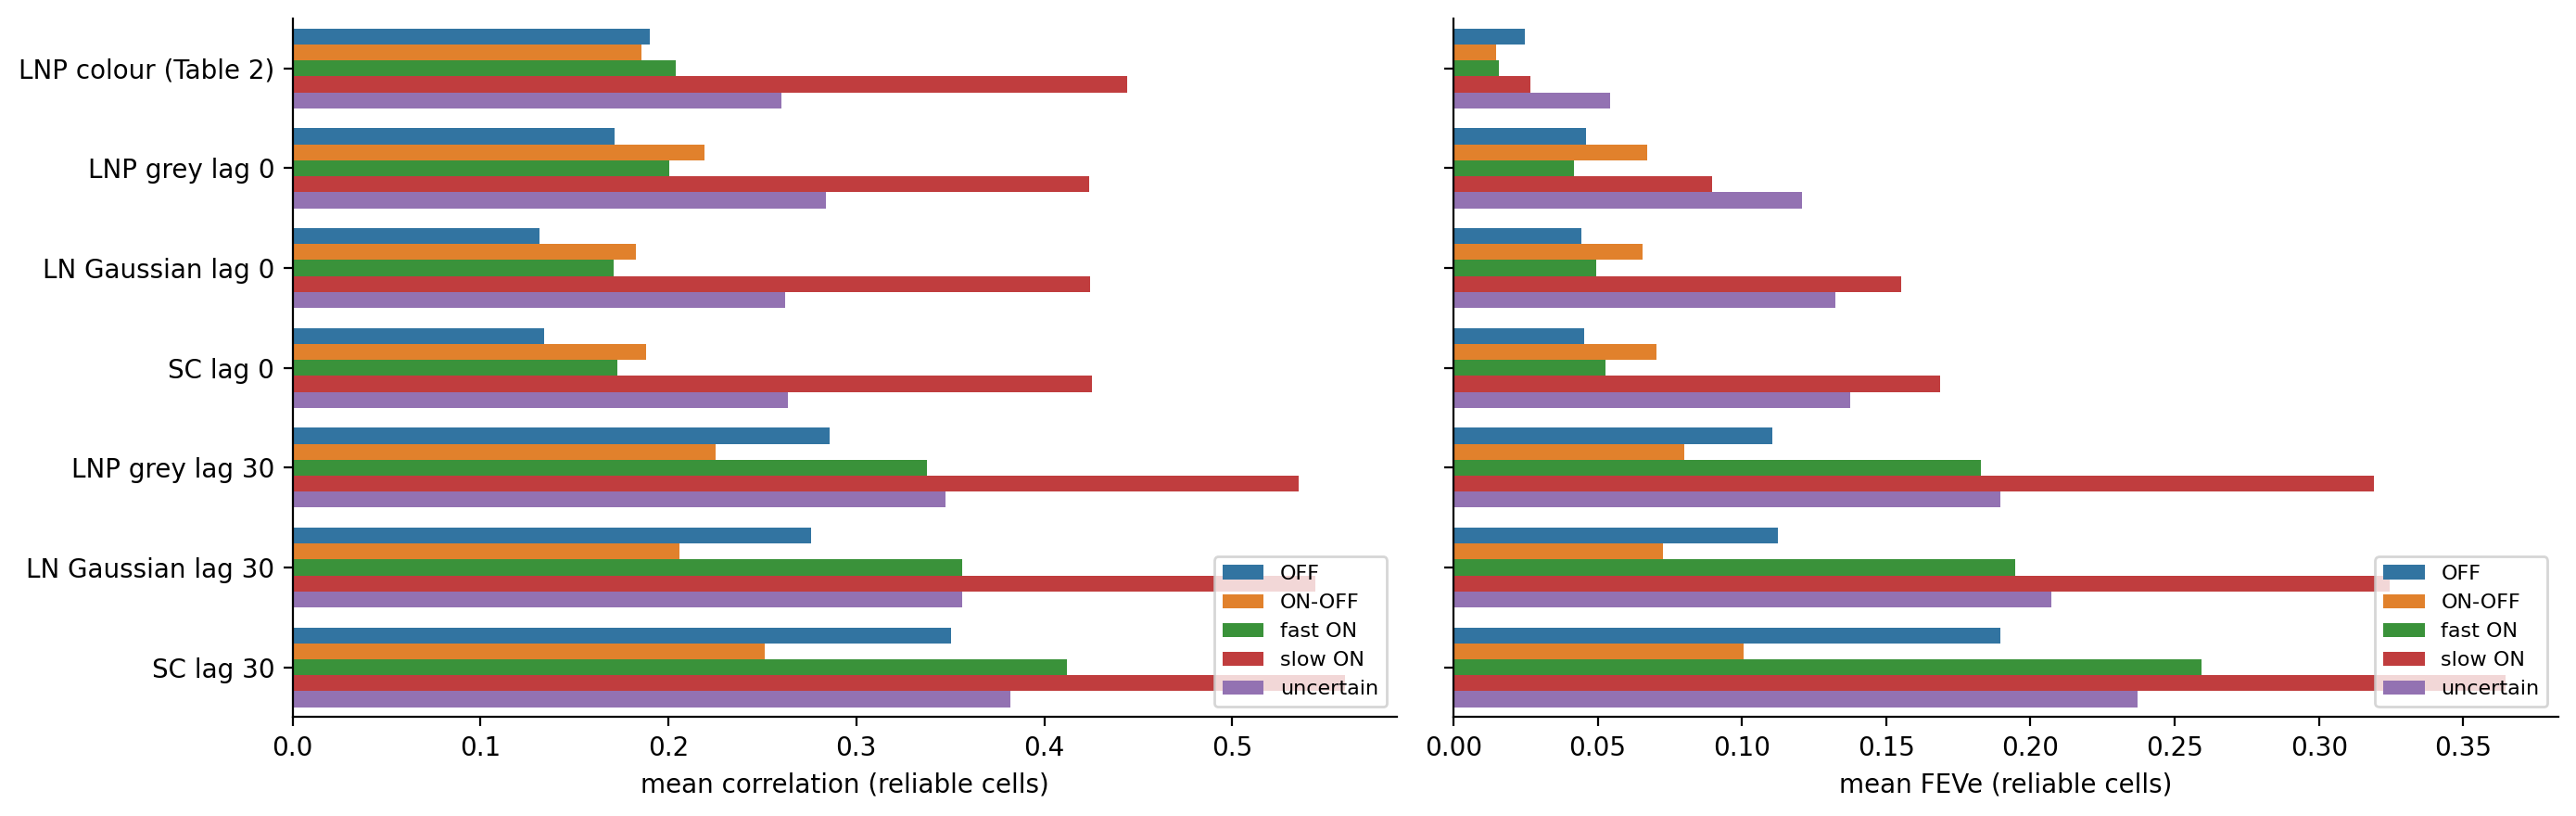

In [9]:
fig, axes = plt.subplots(ncols=2, figsize=(14, 4.5), sharey=True)
for ax, value in zip(axes, ["correlation", "feve"]):
    sns.barplot(
        data=reliable, y="model", x=value, hue="group_class", ax=ax, errorbar=None, order=list(models), orient="h"
    )
    ax.set(xlabel="mean " + ("correlation" if value == "correlation" else "FEVe") + " (reliable cells)", ylabel="")
    ax.legend(title="", fontsize=8, loc="lower right")
sns.despine(fig=fig)
fig.tight_layout()

Cell-by-cell FEVe (reliable cells) for the comparisons that isolate one ingredient at a time: the contrast term (SC vs
LN with the same filters) at lag 0 and lag 30, the lag, and the Gaussian vs the LNP's own filter.

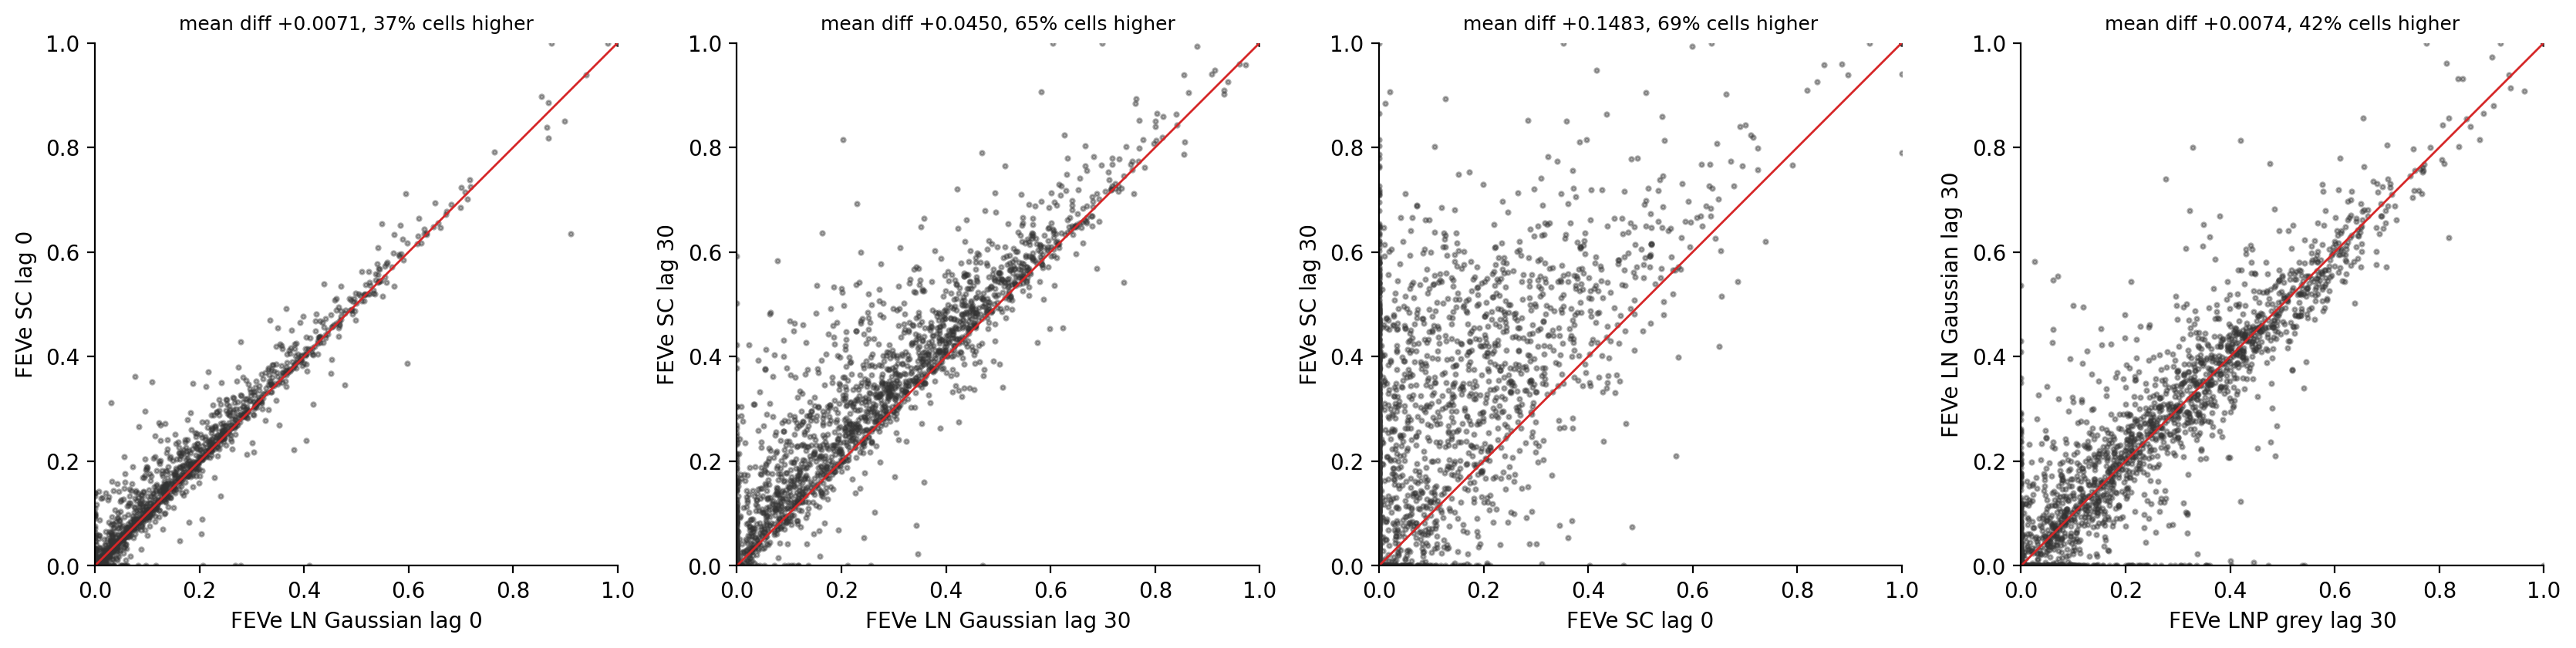

In [10]:
FEVE_PAIRS = [
    ("LN Gaussian lag 0", "SC lag 0"),
    ("LN Gaussian lag 30", "SC lag 30"),
    ("SC lag 0", "SC lag 30"),
    ("LNP grey lag 30", "LN Gaussian lag 30"),
]
FEVE_PAIRS = [(a, b) for a, b in FEVE_PAIRS if a in models and b in models]
feve_wide = reliable.pivot_table(index=["session", "neuron"], columns="model", values="feve")

fig, axes = plt.subplots(ncols=max(len(FEVE_PAIRS), 1), figsize=(4.2 * max(len(FEVE_PAIRS), 1), 4.2), squeeze=False)
for ax, (a, b) in zip(axes[0], FEVE_PAIRS):
    ax.scatter(feve_wide[a], feve_wide[b], s=4, alpha=0.4, color="0.2", rasterized=True)
    ax.plot([0, 1], [0, 1], color="tab:red", lw=1)
    better = (feve_wide[b] > feve_wide[a]).mean()
    ax.set(xlabel=f"FEVe {a}", ylabel=f"FEVe {b}", xlim=(0, 1), ylim=(0, 1), aspect="equal")
    ax.set_title(f"mean diff {(feve_wide[b] - feve_wide[a]).mean():+.4f}, {better:.0%} cells higher", fontsize=9)
sns.despine(fig=fig)
fig.tight_layout()

# Filters

The spatial and temporal filter of a few cells. For the lag-30 LNP these are the two factors the model learns; for the
lag-0 LNP, the learned spatial filter and a single-frame temporal filter. Spatial Contrast filters are the masked
Gaussians and normalised temporal filters the model uses. All filters are shown the way the Spatial Contrast model holds
them: the spatial filter's strongest pixel is positive, so the ON/OFF polarity is in the temporal filter, which has unit
norm. For learned models, the initial Gaussian is outlined in dashes and the initial temporal filter drawn dashed.

The large weight on the current frame (0 ms) is explained in
[Why the temporal filters peak at the current frame](#Why-the-temporal-filters-peak-at-the-current-frame).

Example cells: the reliable cell of each functional group that the reference model predicts best (by correlation).

In [11]:
def lnp_filter_factors(readout, neuron: int) -> tuple[np.ndarray, np.ndarray]:
    """Spatial (H, W) and unit-norm temporal (T,) factor of one LNP neuron's filter, with the spatial filter's strongest
    pixel positive, so that the ON/OFF polarity sits in the temporal filter as in the Spatial Contrast model."""
    with torch.no_grad():
        if isinstance(readout, SeparableLNPReadout):  # the factors the model learns
            spatial = readout.spatial_kernel.weight[neuron, 0, 0].cpu().numpy()
            temporal = readout.temporal_kernel.weight[neuron, 0, :, 0, 0].cpu().numpy()
        else:  # best rank-1 approximation of the full filter, exact for a single frame
            sta = readout.spatiotemporal_filters()[neuron, 0].cpu().numpy()  # (T, H, W)
            u, s, vt = np.linalg.svd(sta.reshape(len(sta), -1), full_matrices=False)
            temporal, spatial = u[:, 0], s[0] * vt[0].reshape(sta.shape[1:])
    sign = np.sign(spatial.flat[np.abs(spatial).argmax()]) or 1.0
    norm = np.linalg.norm(temporal) or 1.0
    return sign * norm * spatial, sign * temporal / norm  # their product is the model's filter


def neuron_filters(model, session: str, neuron: int) -> dict[str, np.ndarray]:
    """Spatial filter (H, W) and temporal filter (T,) of one neuron; index -1 of the temporal filter is the current frame."""
    readout = model.readout[session]
    if isinstance(readout, SpatialContrastReadout):
        with torch.no_grad():
            spatial, temporal, _ = readout._filters()
        filters = {"spatial": spatial[neuron].cpu().numpy(), "temporal": temporal[neuron].cpu().numpy()}
        if isinstance(readout, LearnableFilterSpatialContrastReadout):
            filters["initial_spatial"] = readout.spatial_filters[neuron].cpu().numpy()
            filters["initial_temporal"] = readout.temporal_filters[neuron].cpu().numpy()
        return filters
    spatial, temporal = lnp_filter_factors(readout, neuron)
    return {"spatial": spatial, "temporal": temporal}


reference = reliable[reliable["model"] == (REFERENCE_MODEL if REFERENCE_MODEL in models else next(iter(models)))]
example_cells = [
    (row.session, row.neuron)
    for _, row in reference.sort_values("correlation", ascending=False)
    .groupby("group_class", observed=True)
    .head(1)
    .iterrows()
]
cell_info = metrics.drop_duplicates(["session", "neuron"]).set_index(["session", "neuron"])
example_cells

[('session_1_ventral2_20211130', 11),
 ('session_2_ventral2_20210929', 39),
 ('session_1_ventral2_20200302', 7),
 ('session_2_ventral2_20201022', 34),
 ('session_2_ventral1_20201021', 18)]

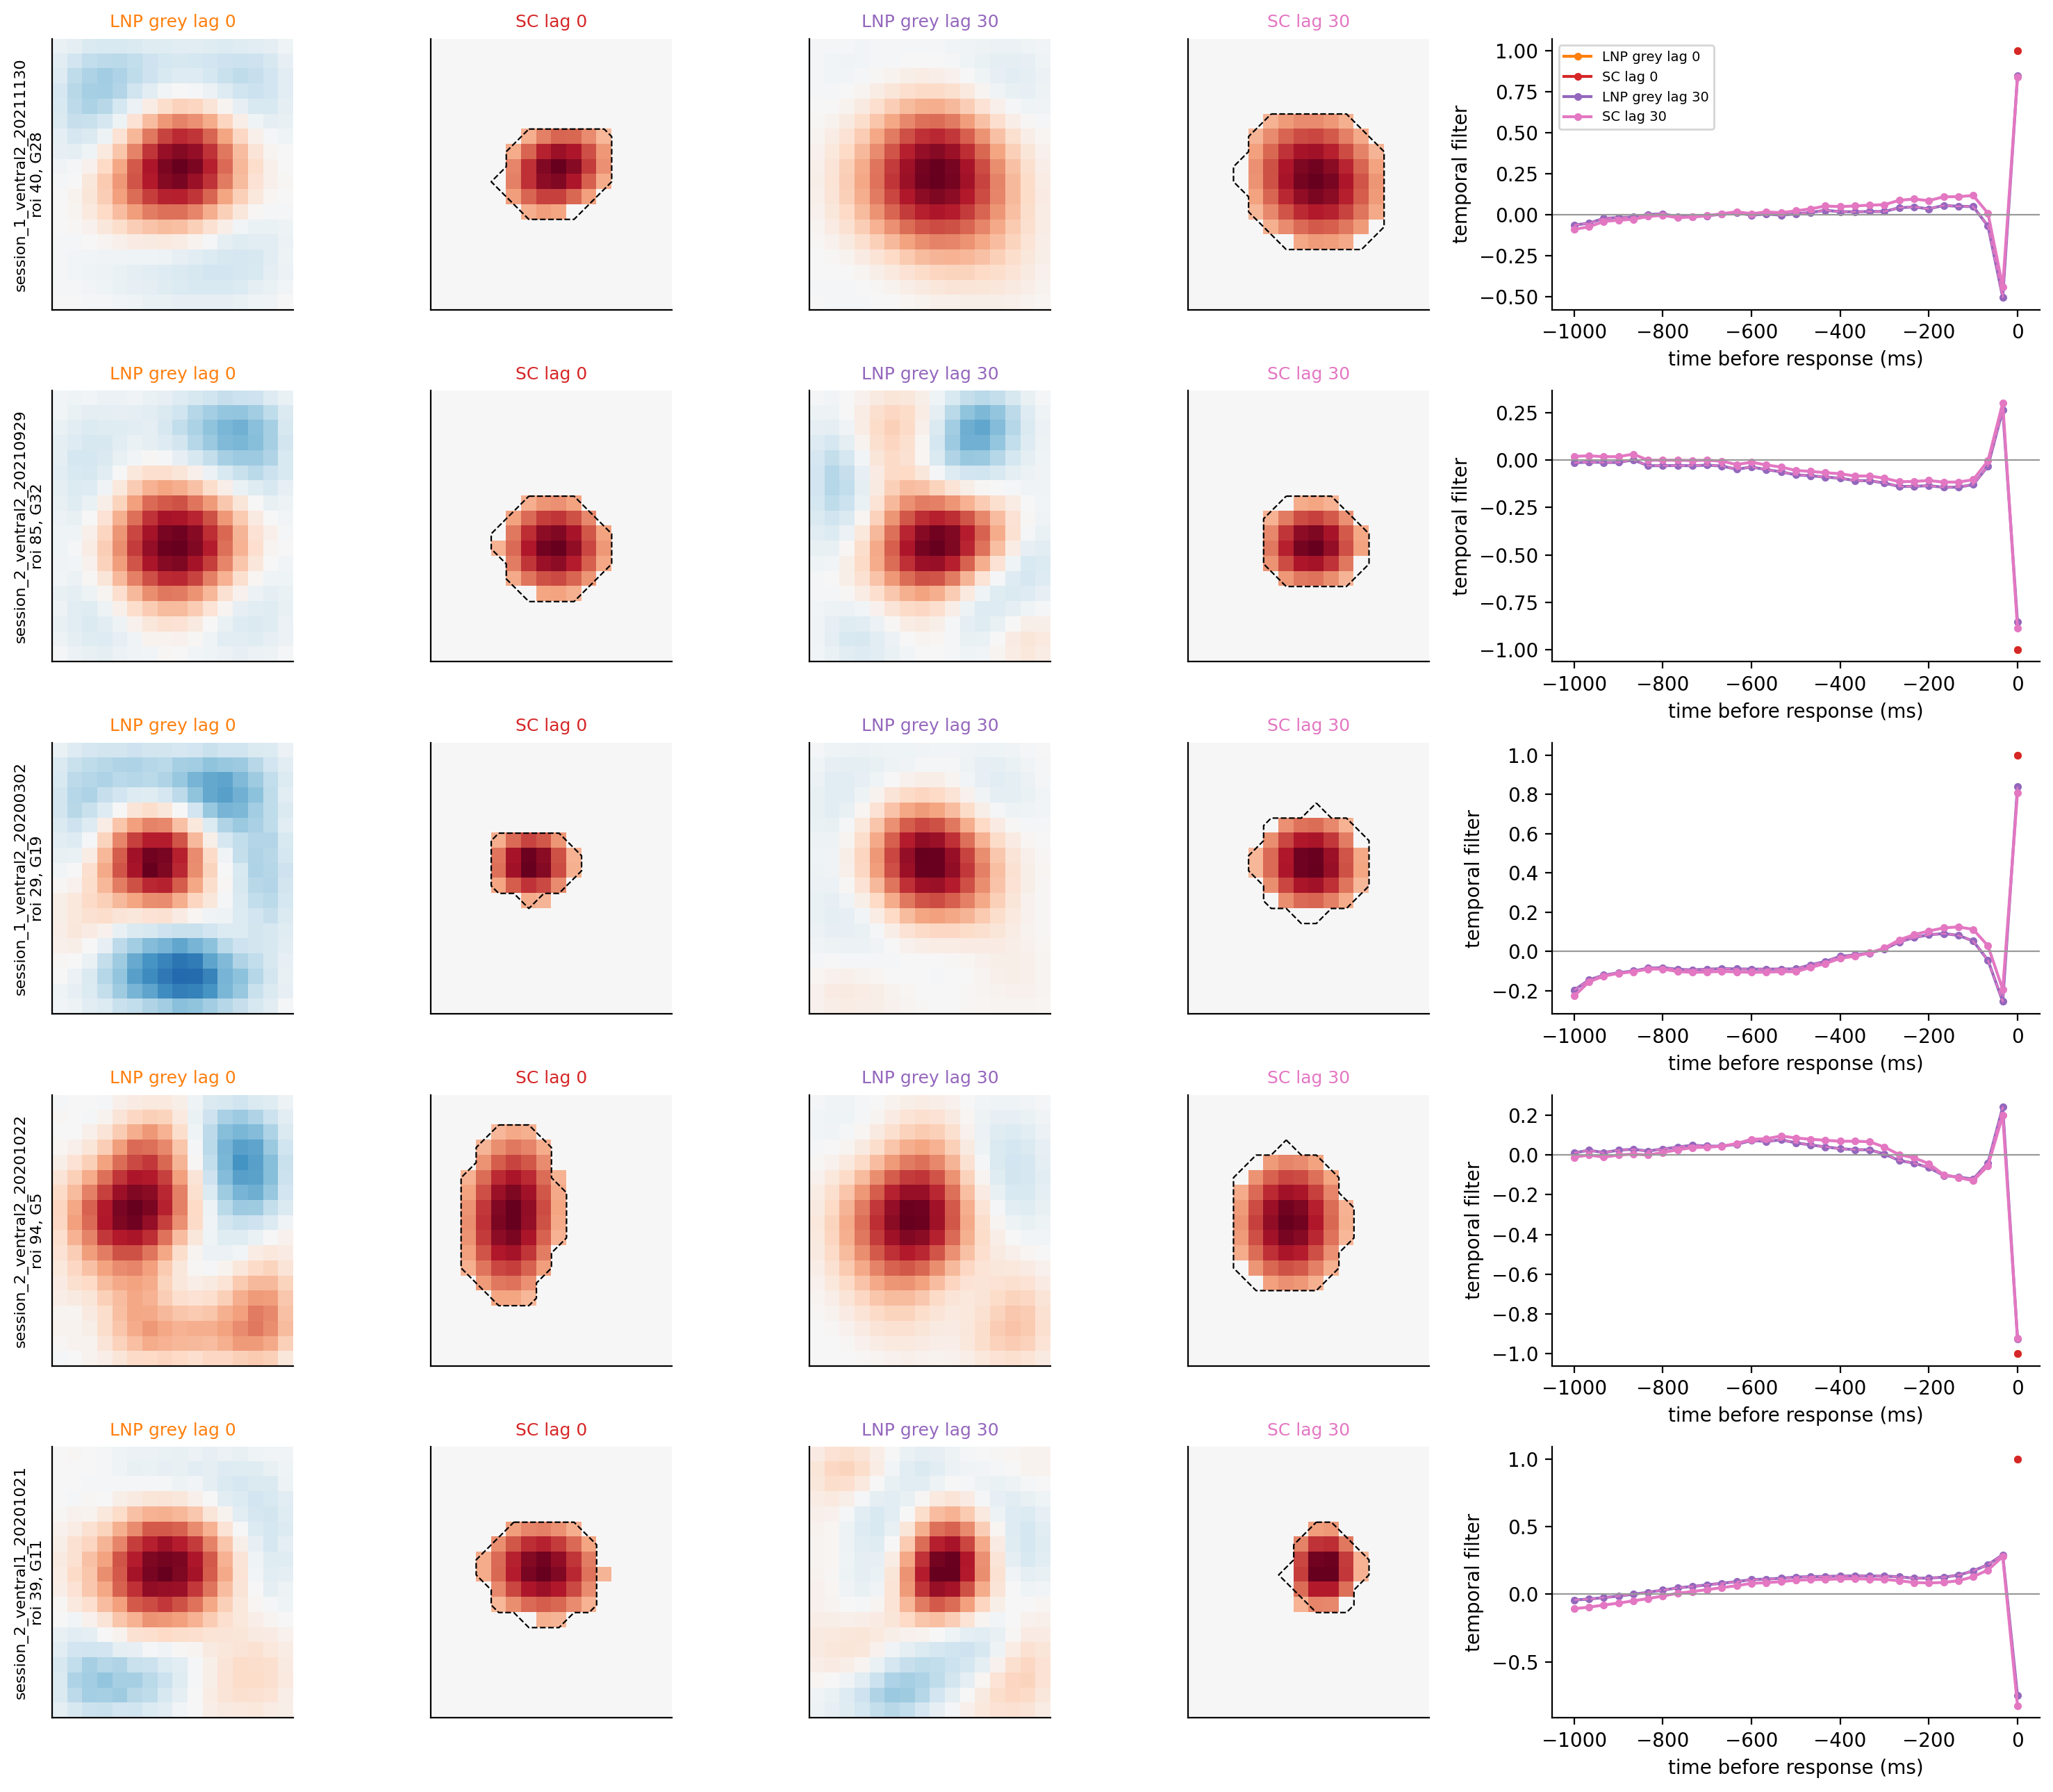

In [12]:
def lags_ms(n_frames: int) -> np.ndarray:
    return np.arange(-n_frames + 1, 1) * 1000 / FRAME_RATE_HZ


fig, axes = plt.subplots(
    nrows=len(example_cells),
    ncols=len(FILTER_MODELS) + 1,
    figsize=(2.6 * len(FILTER_MODELS) + 4.5, 2.6 * len(example_cells)),
    gridspec_kw={"width_ratios": [1] * len(FILTER_MODELS) + [1.8]},
    squeeze=False,
)
for row_axes, (session, neuron) in zip(axes, example_cells):
    info = cell_info.loc[(session, neuron)]
    ax_time = row_axes[-1]
    for ax, label in zip(row_axes[:-1], FILTER_MODELS):
        filters = neuron_filters(models[label], session, neuron)
        spatial = filters["spatial"]
        limit = np.abs(spatial).max() or 1.0
        ax.imshow(spatial, cmap="RdBu_r", vmin=-limit, vmax=limit, interpolation="none")
        if "initial_spatial" in filters:
            ax.contour(filters["initial_spatial"] > 0, levels=[0.5], colors="k", linestyles="--", linewidths=0.8)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(label, fontsize=9, color=palette[label])

        temporal = filters["temporal"]
        ax_time.plot(lags_ms(len(temporal)), temporal, marker="o", ms=3, color=palette[label], label=label)
        if "initial_temporal" in filters:
            initial = filters["initial_temporal"]
            ax_time.plot(lags_ms(len(initial)), initial, ls="--", color=palette[label], lw=0.8)
    row_axes[0].set_ylabel(f"{session}\nroi {info.roi_id}, G{info.group}", fontsize=8)
    ax_time.axhline(0, color="0.6", lw=0.8)
    ax_time.set(xlabel="time before response (ms)", ylabel="temporal filter")
axes[0, -1].legend(fontsize=7)
sns.despine(fig=fig)
fig.tight_layout()

## How far the learned filters moved

For each learned Spatial Contrast model: how far the Gaussian's centre of mass moved from its LNP-derived start, how
its size changed, how much the temporal filter's shape changed (1 - cosine similarity to the initial filter), and the
mean temporal filter per functional group before (dashed) and after (solid) training. The filters start from the LNP
fits and train at a lower learning rate than the nonlinearity, so these are refinements of the LNP filters rather than
independent estimates.

,median centre shift (px),median size ratio,median temporal change
model,,,
LN Gaussian lag 0,0.076552,0.994781,0.000000
LN Gaussian lag 30,0.068261,0.991220,0.005052
SC lag 0,0.076044,0.995203,0.000000
SC lag 30,0.095135,0.984513,0.008867


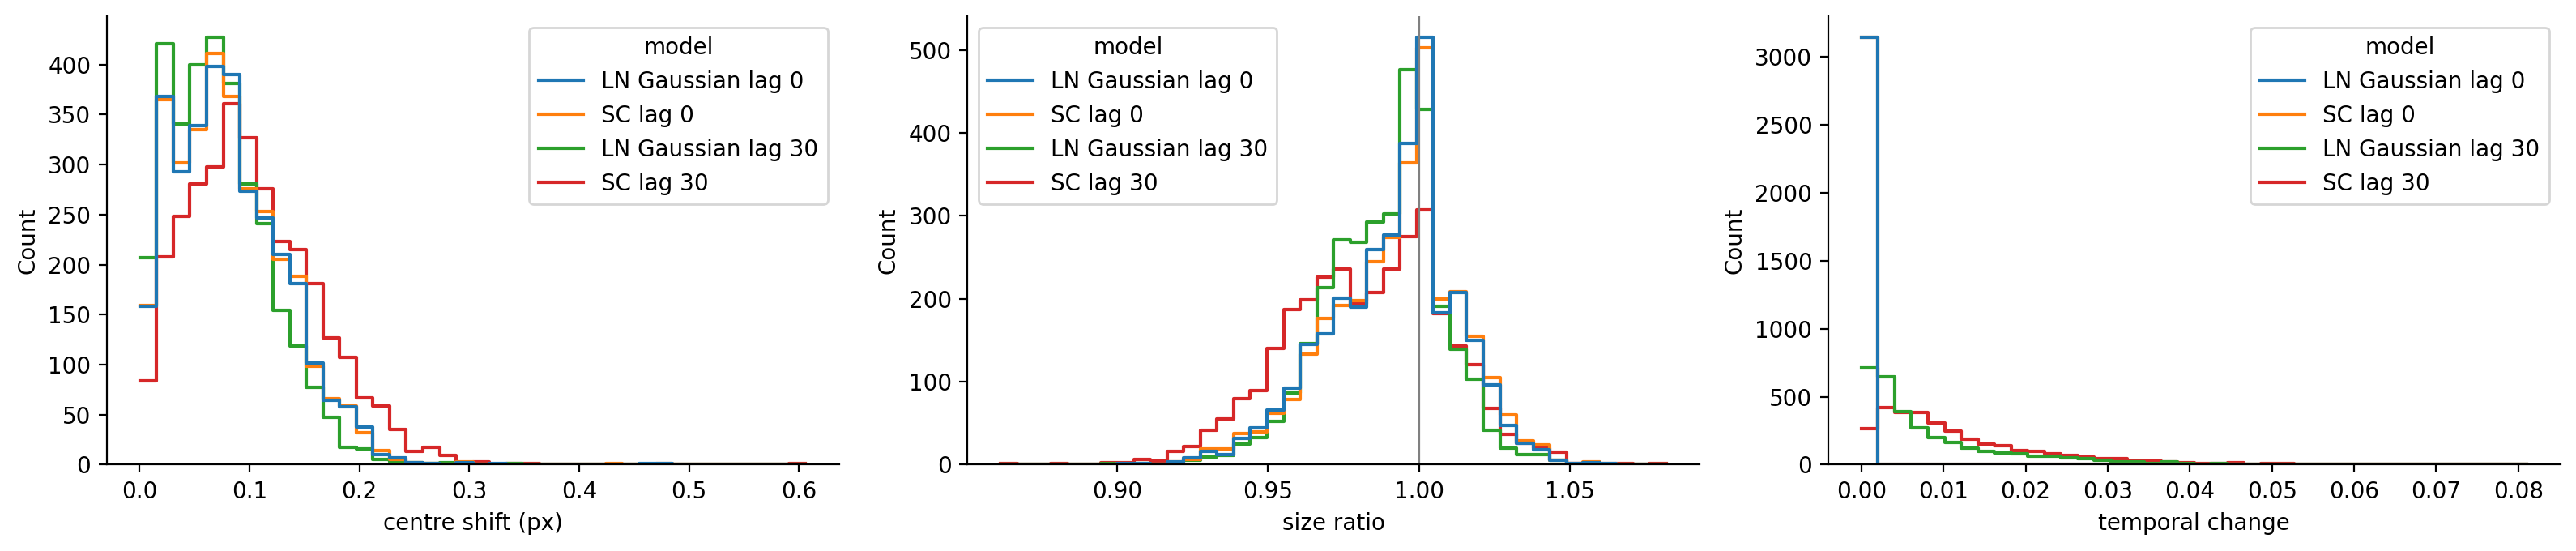

In [13]:
LEARNED_MODELS = [
    label
    for label, model in models.items()
    if any(isinstance(r, LearnableFilterSpatialContrastReadout) for r in model.readout.values())
]


def centre_and_size(spatial: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Centre of mass and RMS radius (pixels) of non-negative maps (N, H, W)."""
    weights = spatial / spatial.sum(axis=(1, 2), keepdims=True)
    y, x = np.mgrid[: spatial.shape[1], : spatial.shape[2]]
    cy, cx = (weights * y).sum(axis=(1, 2)), (weights * x).sum(axis=(1, 2))
    radius = np.sqrt((weights * ((y - cy[:, None, None]) ** 2 + (x - cx[:, None, None]) ** 2)).sum(axis=(1, 2)))
    return np.stack([cy, cx], axis=1), radius


movement_rows, temporal_rows = [], []
for label in LEARNED_MODELS:
    for session in sessions:
        readout = models[label].readout[session]
        with torch.no_grad():
            spatial, temporal, _ = readout._filters()
        active = readout.active.bool().cpu().numpy()
        centre, size = centre_and_size(spatial.cpu().numpy()[active])
        initial_centre, initial_size = centre_and_size(readout.spatial_filters.cpu().numpy()[active])
        learned_temporal = temporal.cpu().numpy()[active]
        initial_temporal = readout.temporal_filters.cpu().numpy()[active]
        cosine = (learned_temporal * initial_temporal).sum(axis=1) / (
            np.linalg.norm(learned_temporal, axis=1) * np.linalg.norm(initial_temporal, axis=1)
        )
        for shift, ratio, change in zip(np.linalg.norm(centre - initial_centre, axis=1), size / initial_size, 1 - cosine):
            movement_rows.append(
                {"model": label, "centre shift (px)": shift, "size ratio": ratio, "temporal change": change}
            )
        groups = final_responses[session].session_kwargs["group_assignment"]
        for neuron in range(len(groups)):
            temporal_rows.append(
                {"model": label, "group": int(groups[neuron]), "stage": "learned", "filter": temporal[neuron].cpu().numpy()}
            )
            temporal_rows.append(
                {
                    "model": label,
                    "group": int(groups[neuron]),
                    "stage": "initial",
                    "filter": readout.temporal_filters[neuron].cpu().numpy(),
                }
            )
movement = pd.DataFrame(movement_rows)

if LEARNED_MODELS:
    fig, axes = plt.subplots(ncols=3, figsize=(16, 3.5))
    sns.histplot(data=movement, x="centre shift (px)", hue="model", element="step", fill=False, ax=axes[0], bins=40)
    sns.histplot(data=movement, x="size ratio", hue="model", element="step", fill=False, ax=axes[1], bins=40)
    sns.histplot(data=movement, x="temporal change", hue="model", element="step", fill=False, ax=axes[2], bins=40)
    axes[1].axvline(1, color="0.5", lw=0.8)
    sns.despine(fig=fig)
    fig.tight_layout()
    display(movement.groupby("model").median().rename(columns=lambda c: f"median {c}"))

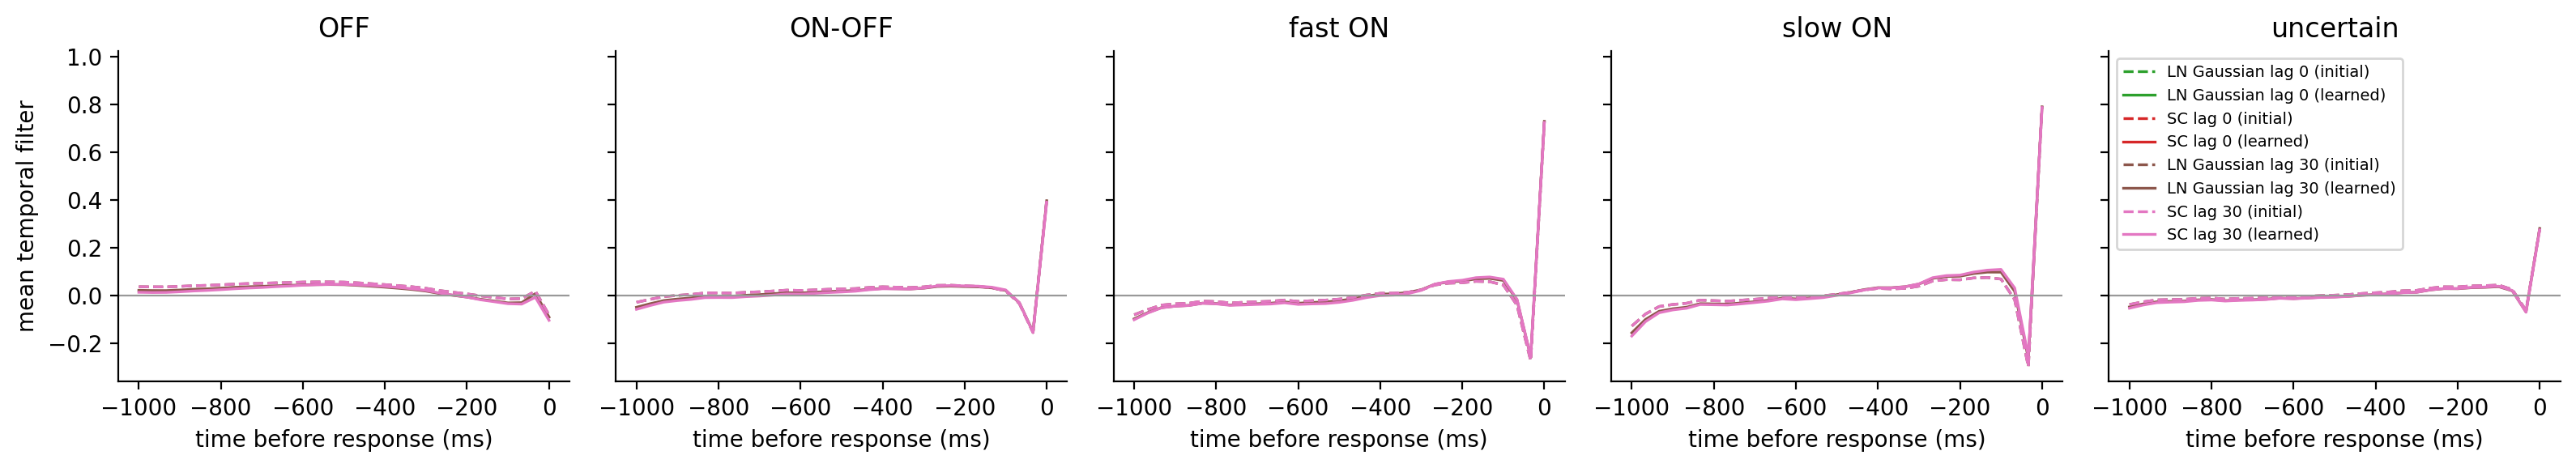

In [14]:
if LEARNED_MODELS:
    temporal_df = pd.DataFrame(temporal_rows)
    temporal_df["group_class"] = pd.cut(
        temporal_df["group"], bins=[0, 9, 14, 20, 28, 32], labels=list(GROUPS), include_lowest=True
    )
    fig, axes = plt.subplots(ncols=len(GROUPS), figsize=(3.2 * len(GROUPS), 3), sharey=True)
    for ax, group_class in zip(axes, GROUPS):
        for label in LEARNED_MODELS:
            for stage, style in [("initial", "--"), ("learned", "-")]:
                selection = temporal_df[
                    (temporal_df.model == label) & (temporal_df.stage == stage) & (temporal_df.group_class == group_class)
                ]
                if selection.empty:
                    continue
                mean_filter = np.stack(selection["filter"].to_list()).mean(axis=0)
                ax.plot(lags_ms(len(mean_filter)), mean_filter, ls=style, color=palette[label], lw=1.2,
                        label=f"{label} ({stage})")
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set(title=group_class, xlabel="time before response (ms)")
    axes[0].set_ylabel("mean temporal filter")
    axes[-1].legend(fontsize=7)
    sns.despine(fig=fig)
    fig.tight_layout()

## Why the temporal filters peak at the current frame

Every lag-30 model above has a large temporal weight on the current frame (0 ms) and an opposite-sign weight on the
frame before. Two things are behind this.

**The opposite-sign pair is left over from the initialisation.** The LNP's temporal kernel starts as a delta on the
current frame (1 there, 0 elsewhere), i.e. as the lag-0 LNP. Natural movies change little from one frame to the next,
so the responses pin down the *sum* of two neighbouring weights much better than their *difference*. After training,
the difference between the current and the previous frame's weight is still close to its starting value in every
cell, while their sum varies from cell to cell, and replacing both weights by their mean, which keeps the sum, leaves
the test correlation unchanged (tables below). Retrained from a uniform start, the opposite sign on the previous frame
disappears (next subsection). The LN and SC models start from the LNP's filters and train them slowly, so they inherit
the pair.

**The weight on the newest frames is not an artefact.** It remains in the uniform-start LNP, where the current frame
still carries the most weight in most cells. The responses are one reason: they are spikes inferred from calcium
imaging, which anticipate the stimulus (last subsection), so the frames just before each response matter most to a
causal model. Trained on the calcium traces instead, the uniform-start LNP's temporal filters mostly peak 100-300 ms
back.

Weights of the lag-30 LNP as stored (the spatial filter carries the polarity there), and its median test correlation
over reliable cells as learned and with the current and previous frame's weights replaced by their mean:

In [15]:
def with_current_and_previous_averaged(model):
    """Copy of a separable LNP whose current and previous frame's temporal weights are replaced by their mean."""
    changed = copy.deepcopy(model)
    with torch.no_grad():
        for readout in changed.readout.values():
            weight = readout.temporal_kernel.weight  # (neurons, 1, time, 1, 1); index -1 is the current frame
            mean = (weight[:, :, -1] + weight[:, :, -2]) / 2
            weight[:, :, -1], weight[:, :, -2] = mean, mean.clone()
    return changed


def test_correlations(model) -> np.ndarray:
    """Correlation of each neuron's prediction with its trial-averaged test response, sessions in order."""
    correlations = []
    for session in sessions:
        test_movie = dataloaders["test"][session].dataset.movies
        with torch.no_grad():
            prediction = model(test_movie.to(model.device).unsqueeze(0), data_key=session).squeeze(0).cpu().numpy()
        target = final_responses[session].test_response.T
        correlations.append(correlation_numpy(target[len(target) - len(prediction) :], prediction, axis=0))
    return np.concatenate(correlations)


def raw_temporal_weights(model) -> np.ndarray:
    """Temporal kernels as stored (neurons, time), sessions in order; index -1 is the current frame."""
    return np.concatenate([model.readout[s].temporal_kernel.weight[:, 0, :, 0, 0].detach().cpu().numpy() for s in sessions])


if REFERENCE_MODEL in models and all(
    isinstance(readout, SeparableLNPReadout) for readout in models[REFERENCE_MODEL].readout.values()
):
    weights = raw_temporal_weights(models[REFERENCE_MODEL])
    display(
        pd.DataFrame(
            {
                "current frame": weights[:, -1],
                "previous frame": weights[:, -2],
                "current - previous": weights[:, -1] - weights[:, -2],
                "current + previous": weights[:, -1] + weights[:, -2],
            }
        )
        .quantile([0.25, 0.5, 0.75])
        .rename(index=lambda q: f"{q:.0%} quantile")
        .round(3)
    )
    reliable_cells = metrics.loc[metrics["model"] == REFERENCE_MODEL, "reliable"].to_numpy()  # same cell order
    variants = {
        "as learned": models[REFERENCE_MODEL],
        "current and previous frame averaged": with_current_and_previous_averaged(models[REFERENCE_MODEL]),
    }
    display(
        pd.DataFrame(
            {label: [np.median(test_correlations(model)[reliable_cells])] for label, model in variants.items()},
            index=[f"{REFERENCE_MODEL}, median test correlation"],
        ).round(3)
    )

,current frame,previous frame,current - previous,current + previous
25% quantile,0.577,-0.273,0.805,0.308
50% quantile,0.631,-0.229,0.852,0.401
75% quantile,0.672,-0.181,0.891,0.483


,as learned,current and previous frame averaged
"LNP grey lag 30, median test correlation",0.402,0.405


### Retraining without the delta

The lag-30 LNP retrained with every frame starting at the same weight, 1/31 (`+model.readout.temporal_init=uniform`),
next to the original. Both were also trained on responses delayed by a few frames
(`data_io.responses.response_delay_frames`) and on the calcium traces (`+data_io.responses.trace_type=preprocessed`),
to see how much of the current-frame weight follows the response timing. The figure shows the mean temporal filter per
group against time from the recorded response, so a delayed model's filter is shifted right by its delay. The table
gives where each cell's temporal filter peaks, and each model's median test correlation over reliable cells. Only the
models trained on the undelayed spikes are scored against the Table 2 targets; the others are scored on their own
responses (delayed, or calcium), which are not comparable.

The uniform start removes the opposite-sign pair, but leaves a negative weight on the oldest frames instead (where
the median peak of its delayed version lands) and trains to a lower test correlation, so the models above keep the
current-frame start. Delaying the responses moves weight away from the current frame without improving the
predictions, so the response timing explains part of the current-frame weight, not all of it.

,delay (frames),peak on current frame,current and previous frame opposite,median peak (ms from response),median test corr,scored on
model,,,,,,
LNP grey lag 30,0,0.997,0.999,0.0,0.402,Table 2 targets
delay 3 frames,3,0.997,1.000,100.0,0.401,own responses
delay 6 frames,6,0.957,1.000,200.0,0.395,own responses
delay 9 frames,9,0.967,1.000,300.0,0.380,own responses
calcium,0,0.957,1.000,0.0,0.518,own responses
uniform init,0,0.736,0.043,0.0,0.388,Table 2 targets
"uniform init, delay 6 frames",6,0.361,0.065,-800.0,0.392,own responses
"uniform init, calcium",0,0.215,0.246,-300.0,0.518,own responses


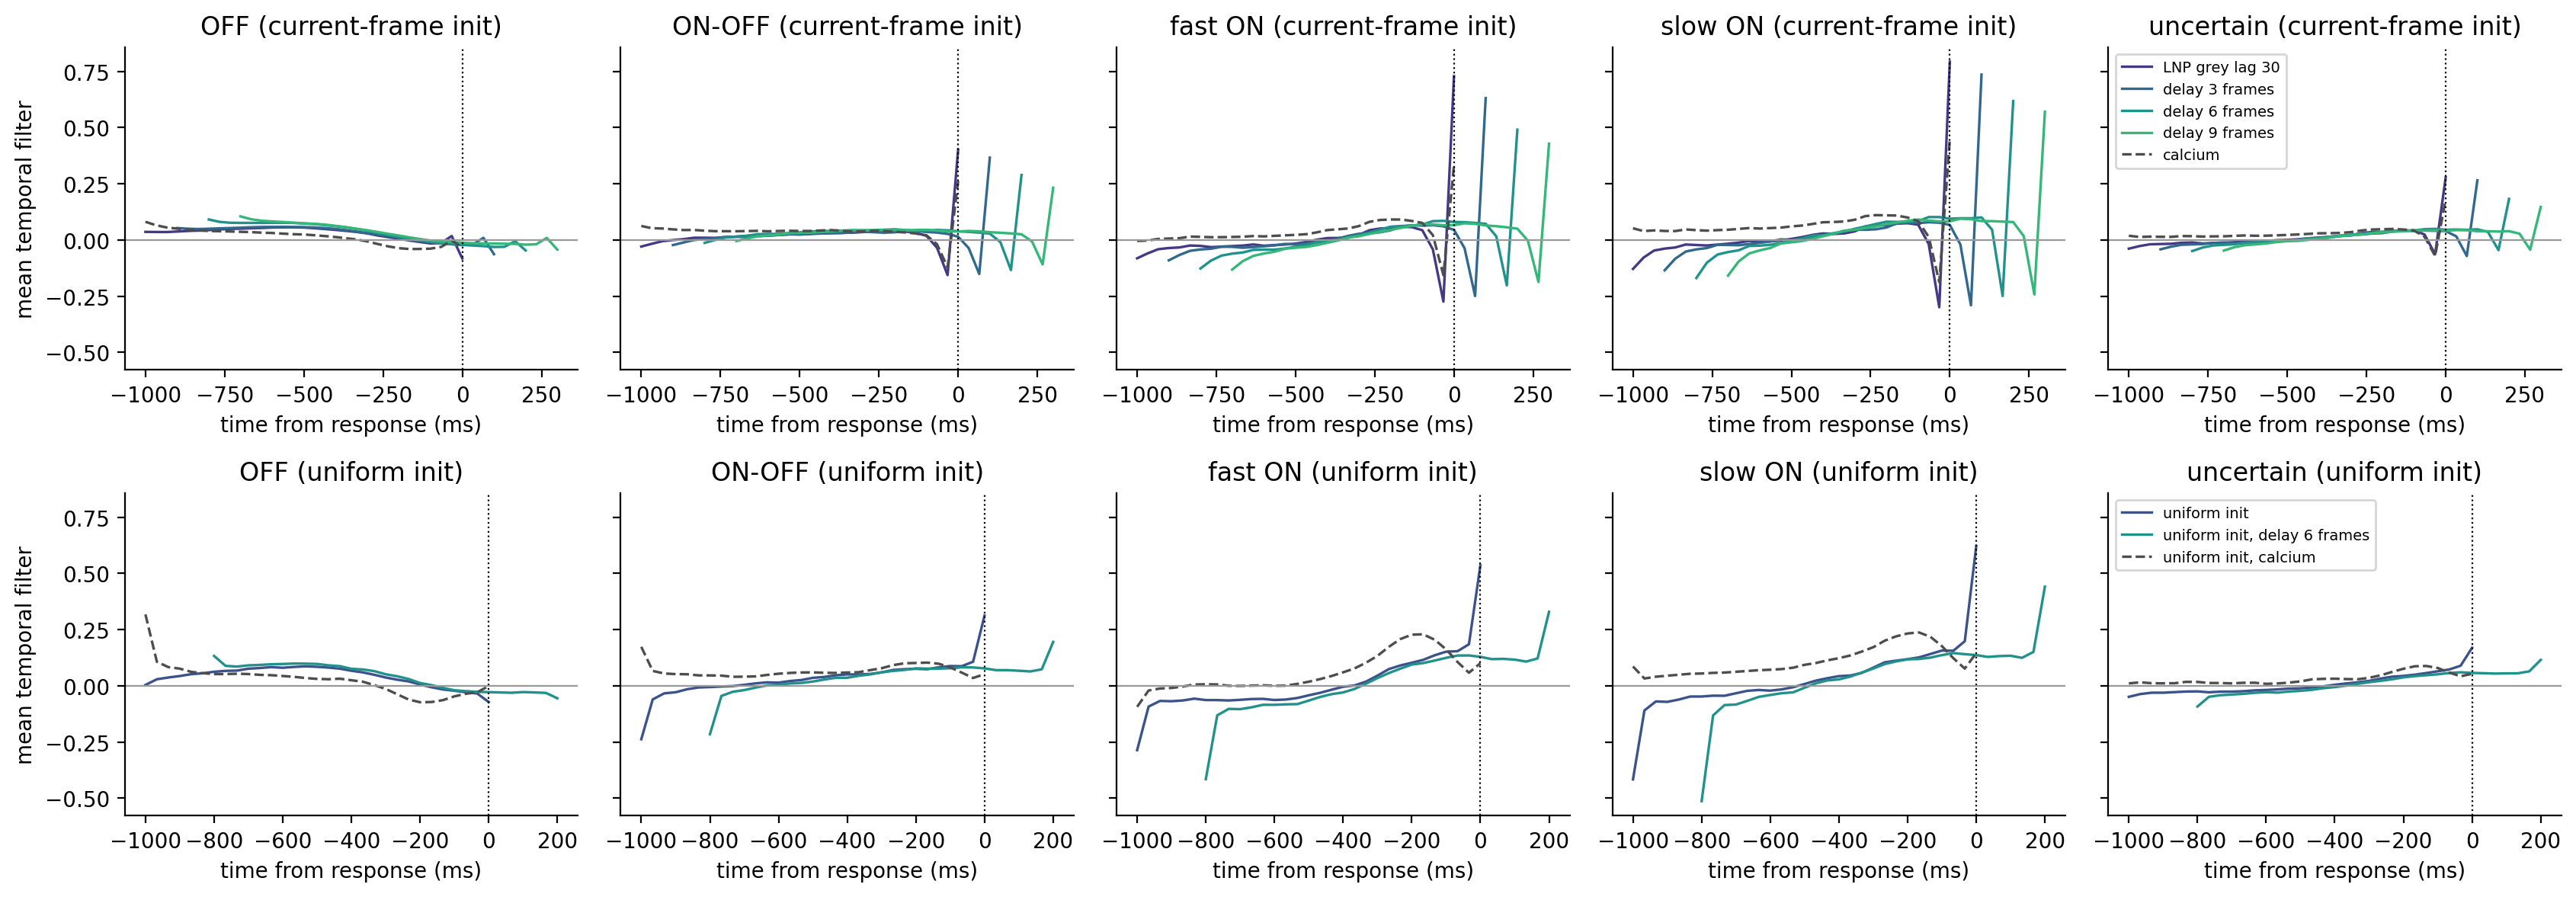

In [16]:
diagnostic_models = {}
if REFERENCE_MODEL in models:
    diagnostic_models[REFERENCE_MODEL] = models[REFERENCE_MODEL]
for label, location in DIAGNOSTIC_LNPS.items():
    checkpoint = resolve_checkpoint(location)
    if checkpoint is None:
        print(f"skipping {label}: nothing at {location}")
        continue
    diagnostic_models[label] = load_core_readout_model(checkpoint, device).eval()

all_groups = np.concatenate([final_responses[s].session_kwargs["group_assignment"] for s in sessions]).astype(int)
reliable_cells = metrics.loc[metrics["model"] == next(iter(models)), "reliable"].to_numpy()
summary_rows, mean_filters = [], {}
for label, model in diagnostic_models.items():
    delay = int(model.data_info.get("response_delay_frames", 0))
    on_table2_targets = delay == 0 and "calcium" not in label
    temporal = np.concatenate(
        [
            np.stack([lnp_filter_factors(model.readout[s], n)[1] for n in range(model.readout[s].number_of_neurons())])
            for s in sessions
        ]
    )  # (neurons, time), unit norm, polarity in the temporal filter; index -1 is the current frame
    frames_before = temporal.shape[1] - 1 - np.abs(temporal).argmax(axis=1)  # where each filter peaks
    if on_table2_targets:
        correlations = test_correlations(model)
    else:
        correlations = np.concatenate(
            [torch.as_tensor(model.data_info["pretrained_performance"][s]).cpu().numpy() for s in sessions]
        )
    summary_rows.append(
        {
            "model": label,
            "delay (frames)": delay,
            "peak on current frame": np.mean(frames_before == 0),
            "current and previous frame opposite": np.mean(np.sign(temporal[:, -1]) != np.sign(temporal[:, -2])),
            "median peak (ms from response)": np.median(delay - frames_before) * 1000 / FRAME_RATE_HZ,
            "median test corr": np.median(correlations[reliable_cells]),
            "scored on": "Table 2 targets" if on_table2_targets else "own responses",
        }
    )
    mean_filters[label] = (
        lags_ms(temporal.shape[1]) + delay * 1000 / FRAME_RATE_HZ,
        {c: temporal[(all_groups >= lo) & (all_groups <= hi)].mean(axis=0) for c, (lo, hi) in GROUPS.items()},
    )

display(pd.DataFrame(summary_rows).set_index("model").round(3))

# One row per temporal initialisation
rows = {
    "current-frame init": [label for label in mean_filters if "uniform" not in label],
    "uniform init": [label for label in mean_filters if "uniform" in label],
}
rows = {title: labels for title, labels in rows.items() if labels}
fig, axes = plt.subplots(
    nrows=len(rows), ncols=len(GROUPS), figsize=(3.4 * len(GROUPS), 3.0 * len(rows)), sharey=True, squeeze=False
)
for row_axes, (title, labels) in zip(axes, rows.items()):
    colors = sns.color_palette("viridis", n_colors=len(labels))
    for color, label in zip(colors, labels):
        times_ms, by_class = mean_filters[label]
        style = {"color": "0.3", "ls": "--"} if "calcium" in label else {"color": color, "ls": "-"}
        for ax, group_class in zip(row_axes, GROUPS):
            ax.plot(times_ms, by_class[group_class], lw=1.2, label=label, **style)
    for ax, group_class in zip(row_axes, GROUPS):
        ax.axvline(0, color="k", lw=0.8, ls=":")
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set(title=f"{group_class} ({title})", xlabel="time from response (ms)")
    row_axes[0].set_ylabel("mean temporal filter")
    row_axes[-1].legend(fontsize=7)
sns.despine(fig=fig)
fig.tight_layout()

### Timing of the inferred spikes

Separately from the initialisation, the responses all these models fit are spikes inferred from calcium imaging at
7.8 Hz and interpolated to the 30 Hz stimulus frames, and spike inference is not causal. Around the chirp's light steps
below, the inferred spikes start rising ~200 ms *before* the step, while the calcium signal they are inferred from only
rises after it. A response at frame t therefore partly reflects frames after t, so the timing of a filter relative to
the response is not a physiological latency. This holds for every Table 2 model, the CNN included.

Average calcium signal and inferred spikes around the light-on step (ON cells) and the light-off step (OFF cells) of
the chirp, over the analysed cells and all chirp repeats:

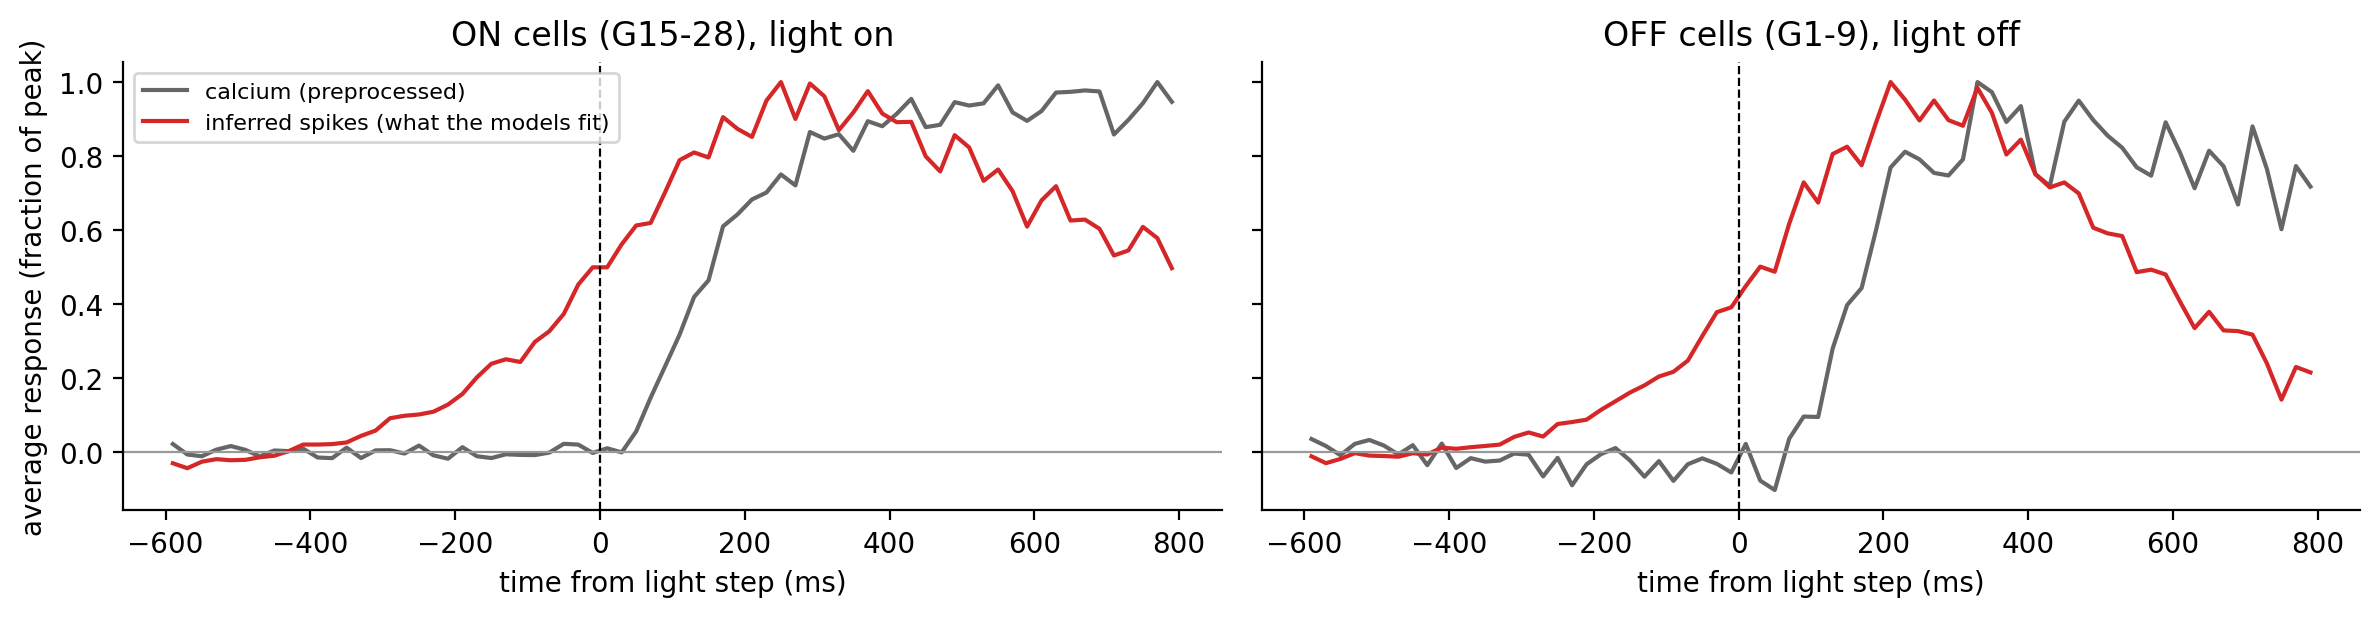

In [17]:
CHIRP_STEPS = {  # cells (first and last group) and the light step they respond to
    "ON cells (G15-28), light on": (15, 28, "on"),
    "OFF cells (G1-9), light off": (1, 9, "off"),
}
CHIRP_SIGNALS = {  # signal: (traces, their time stamps) in the responses file
    "calcium (preprocessed)": ("chirp_preprocessed_traces", "chirp_traces_times"),
    "inferred spikes (what the models fit)": ("chirp_spikes", "chirp_spike_times"),
}
STEP_BINS = np.arange(-0.6, 0.8001, 0.02)  # s around the step


def step_average(traces_key: str, times_key: str, first_group: int, last_group: int, step: str) -> np.ndarray:
    """Average of a chirp signal around a light step, over the analysed cells of some groups and all chirp repeats.

    Each cell is scaled by its standard deviation, and each repeat baseline-subtracted over 0.6 to 0.3 s before the
    step (later than that, the inferred spikes are already rising). Every cell is sampled at 7.8 Hz at its own phase,
    so pooling cells resolves the average more finely than that.
    """
    total, count = np.zeros(len(STEP_BINS) - 1), np.zeros(len(STEP_BINS) - 1)
    for session in sessions:
        raw = responses_dict[session]
        groups = final_responses[session].session_kwargs["group_assignment"]
        roi_ids = final_responses[session].session_kwargs["roi_ids"][(groups >= first_group) & (groups <= last_group)]
        # Two triggers per chirp: its start, and the light-off step 5 s in, after 2 s dark and 3 s light
        triggers = raw["chirp_trigger_times"][0]
        starts, light_off = triggers[::2], triggers[1::2]
        step_times = starts + 0.4 * (light_off - starts) if step == "on" else light_off
        for row in np.flatnonzero(np.isin(raw["roi_ids"], roi_ids.astype(int))):
            trace, times = raw[traces_key][row].astype(float), raw[times_key][row]
            valid = np.isfinite(trace)
            trace, times = trace[valid] / (trace[valid].std() + 1e-9), times[valid]
            for step_time in step_times:
                relative = times - step_time
                baseline = trace[(relative >= STEP_BINS[0]) & (relative < -0.3)]
                inside = (relative >= STEP_BINS[0]) & (relative < STEP_BINS[-1])
                if baseline.size == 0:
                    continue
                bins = np.digitize(relative[inside], STEP_BINS) - 1
                np.add.at(total, bins, trace[inside] - baseline.mean())
                np.add.at(count, bins, 1)
    return total / np.maximum(count, 1)


step_centres_ms = 1000 * (STEP_BINS[:-1] + STEP_BINS[1:]) / 2
fig, axes = plt.subplots(ncols=len(CHIRP_STEPS), figsize=(6 * len(CHIRP_STEPS), 3.2), sharey=True)
for ax, (title, (first_group, last_group, step)) in zip(axes, CHIRP_STEPS.items()):
    for (label, (traces_key, times_key)), color in zip(CHIRP_SIGNALS.items(), ["0.4", "C3"]):
        average = step_average(traces_key, times_key, first_group, last_group, step)
        ax.plot(step_centres_ms, average / np.abs(average).max(), color=color, label=label)
    ax.axvline(0, color="k", lw=0.8, ls="--")
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set(title=title, xlabel="time from light step (ms)")
axes[0].set_ylabel("average response (fraction of peak)")
axes[0].legend(fontsize=8, loc="upper left")
sns.despine(fig=fig)
fig.tight_layout()

# Predictions

Recorded responses to the test movie (grey: the three repeats, black: their mean) with each model's prediction. The
shaded start is cut by every model; dotted lines separate the five test clips.

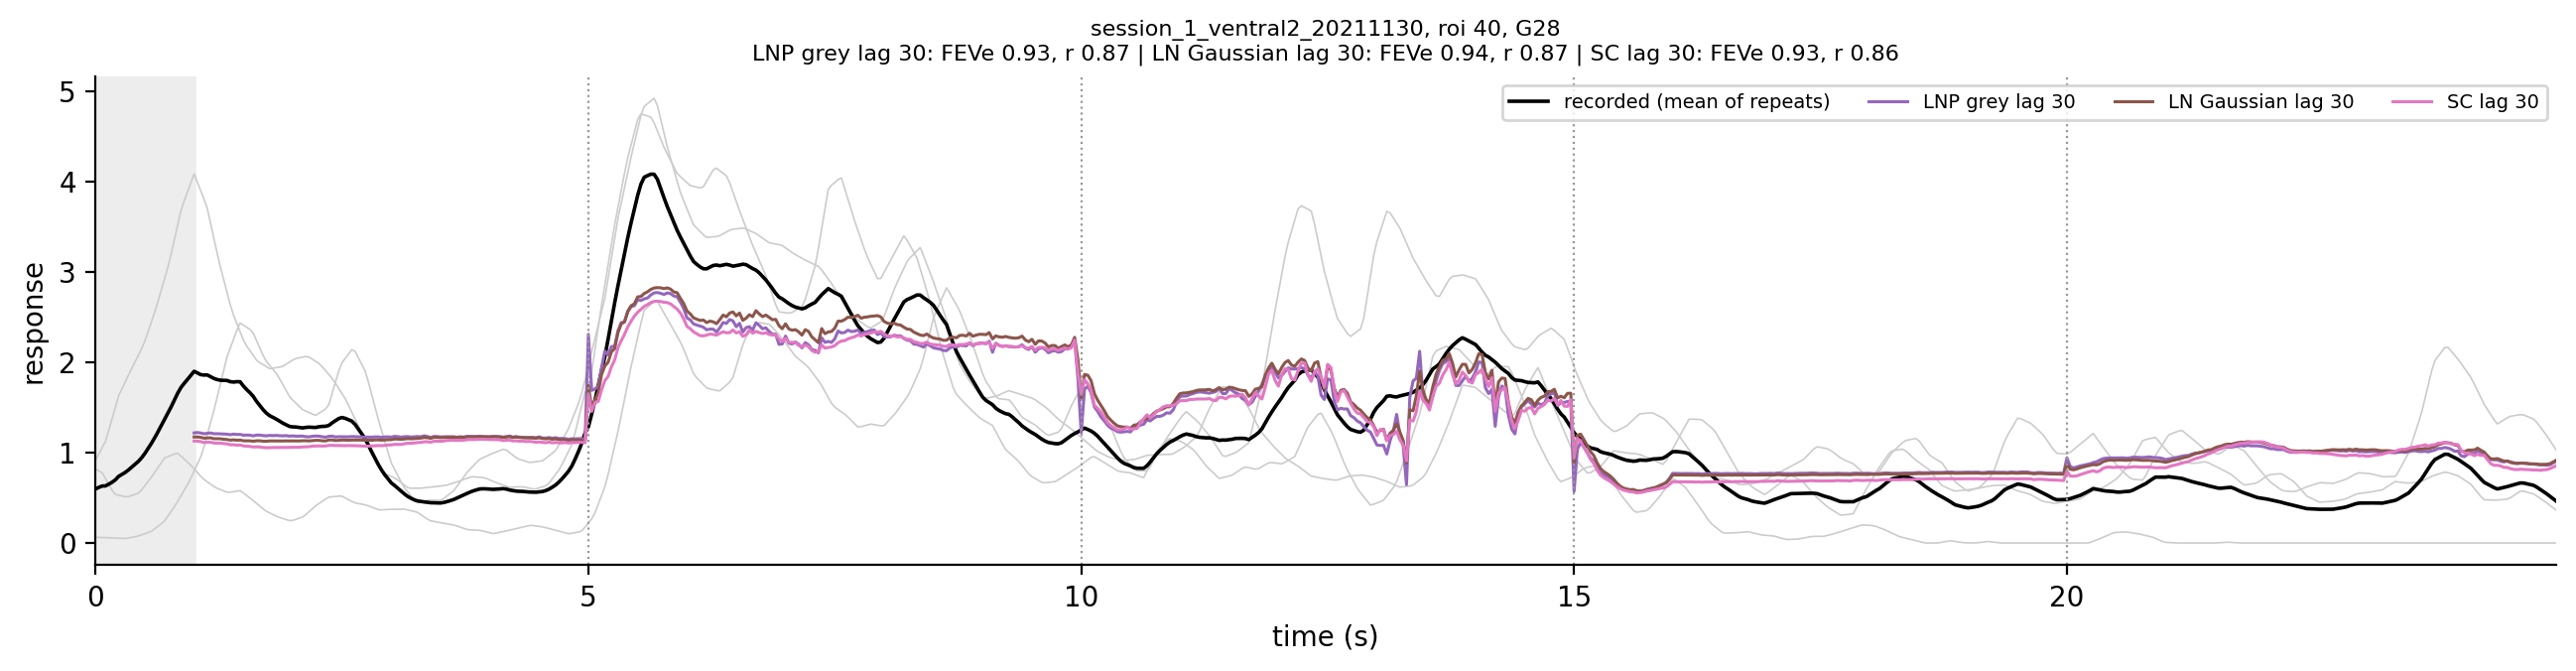

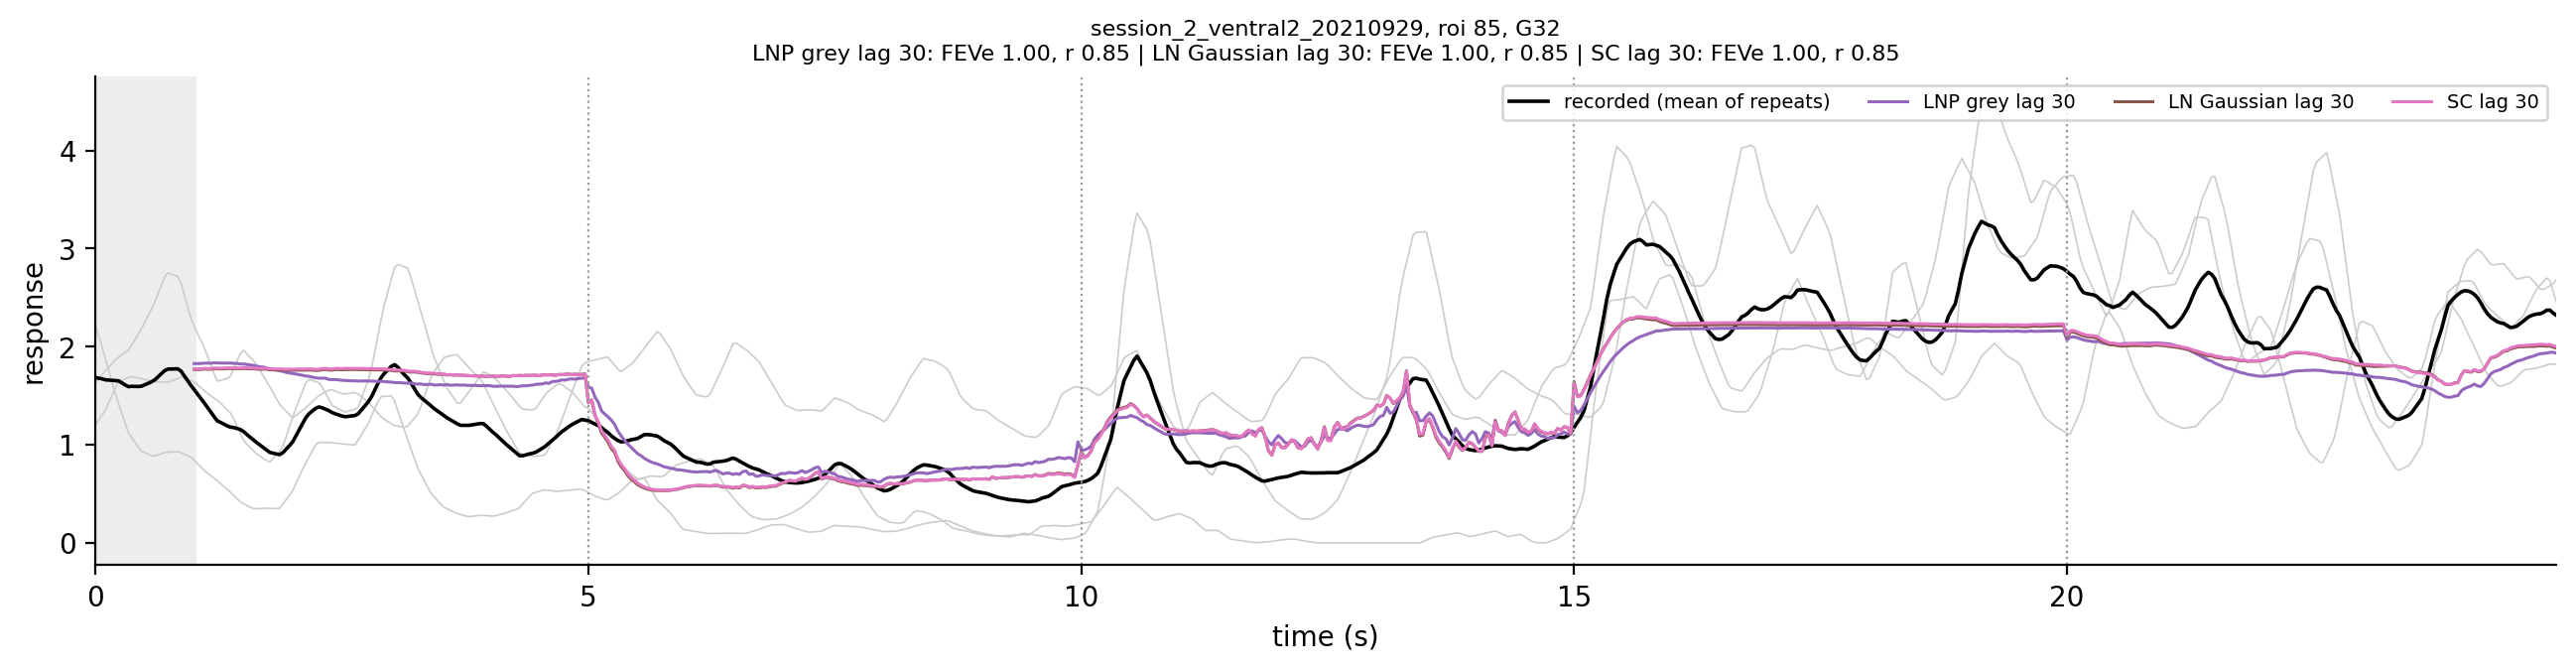

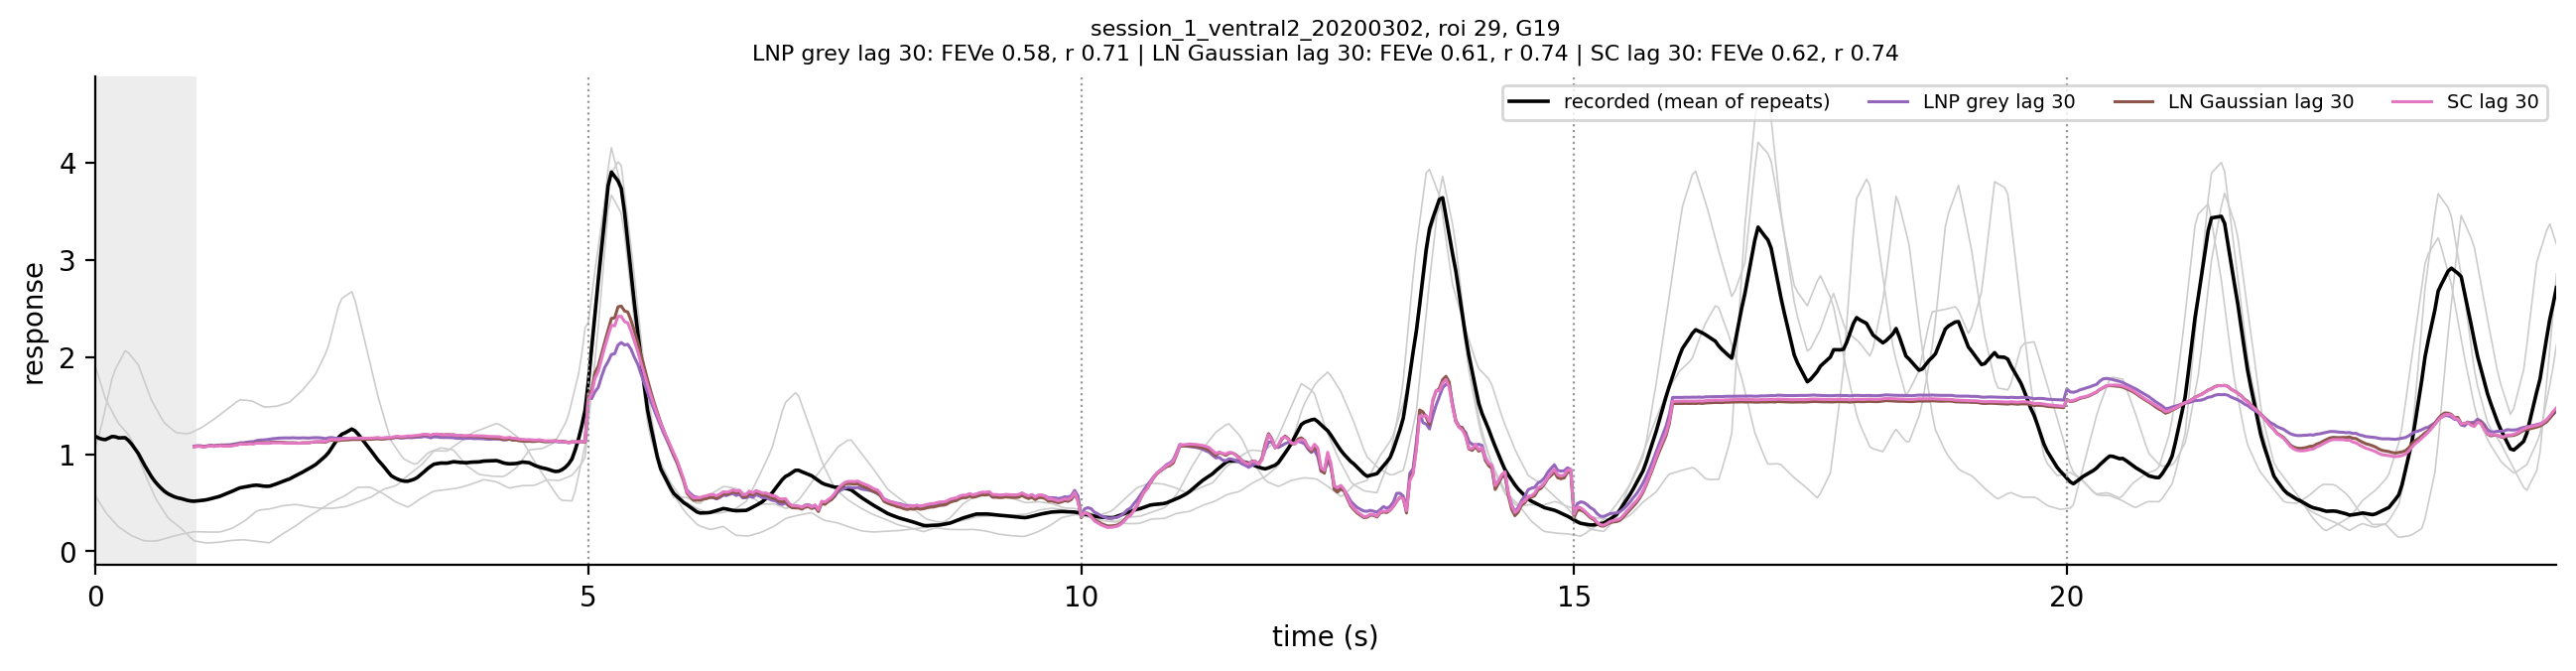

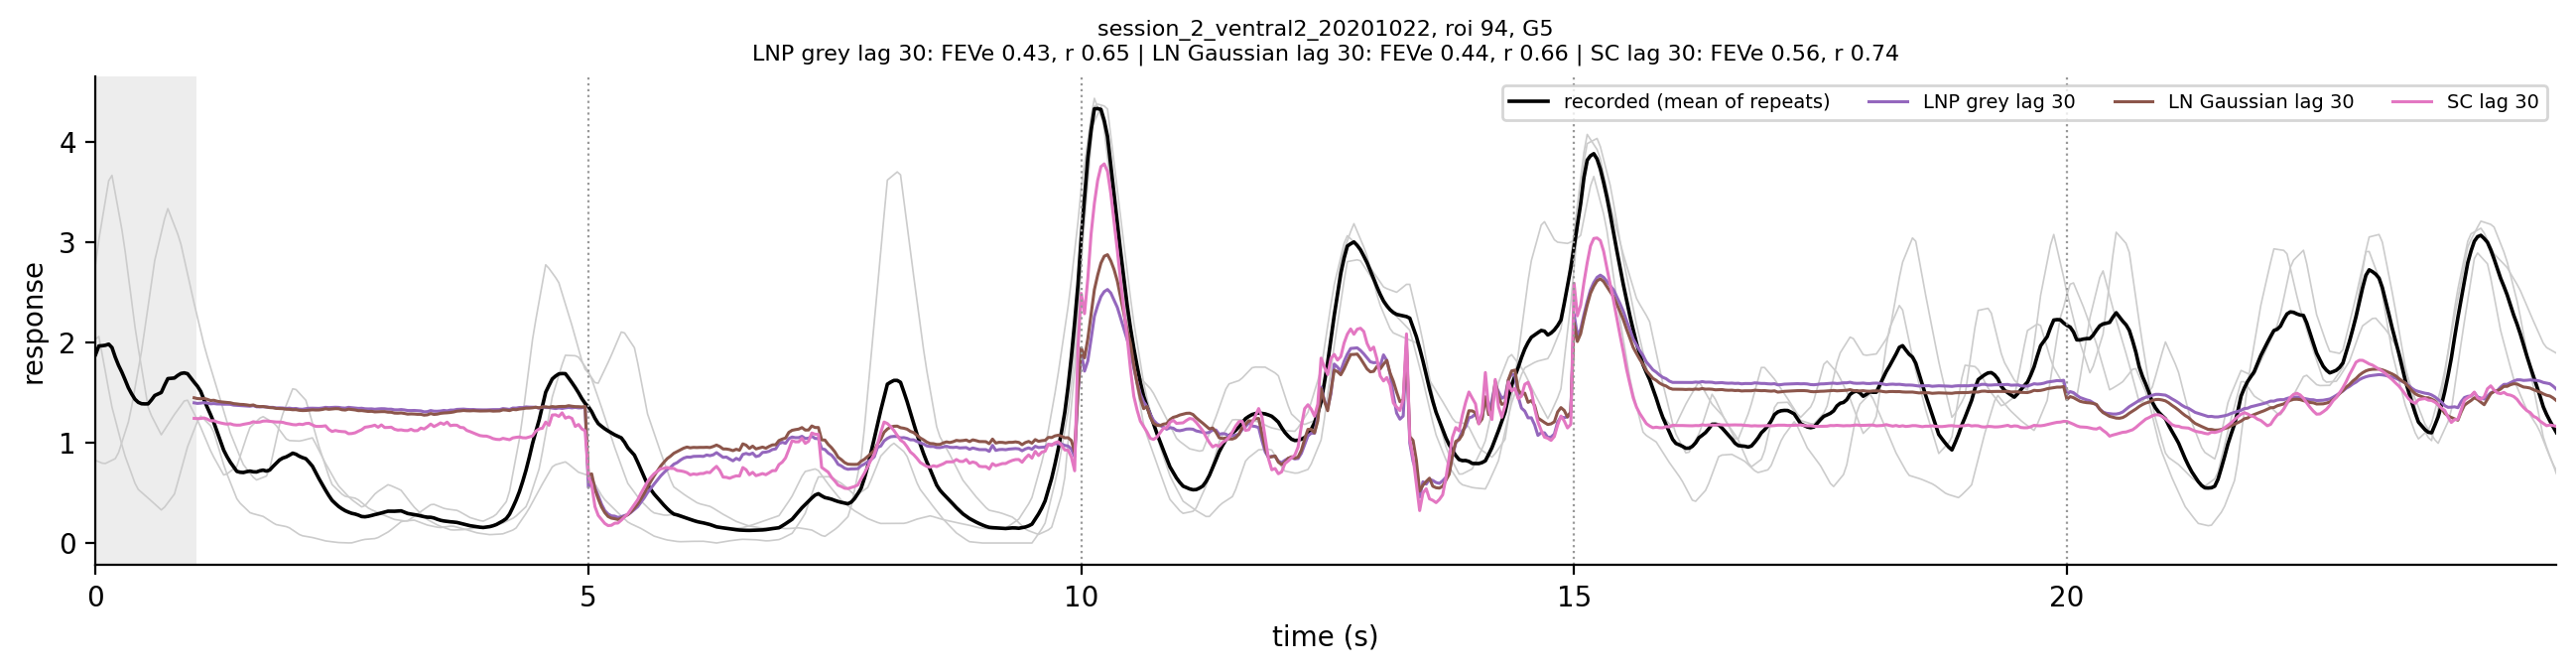

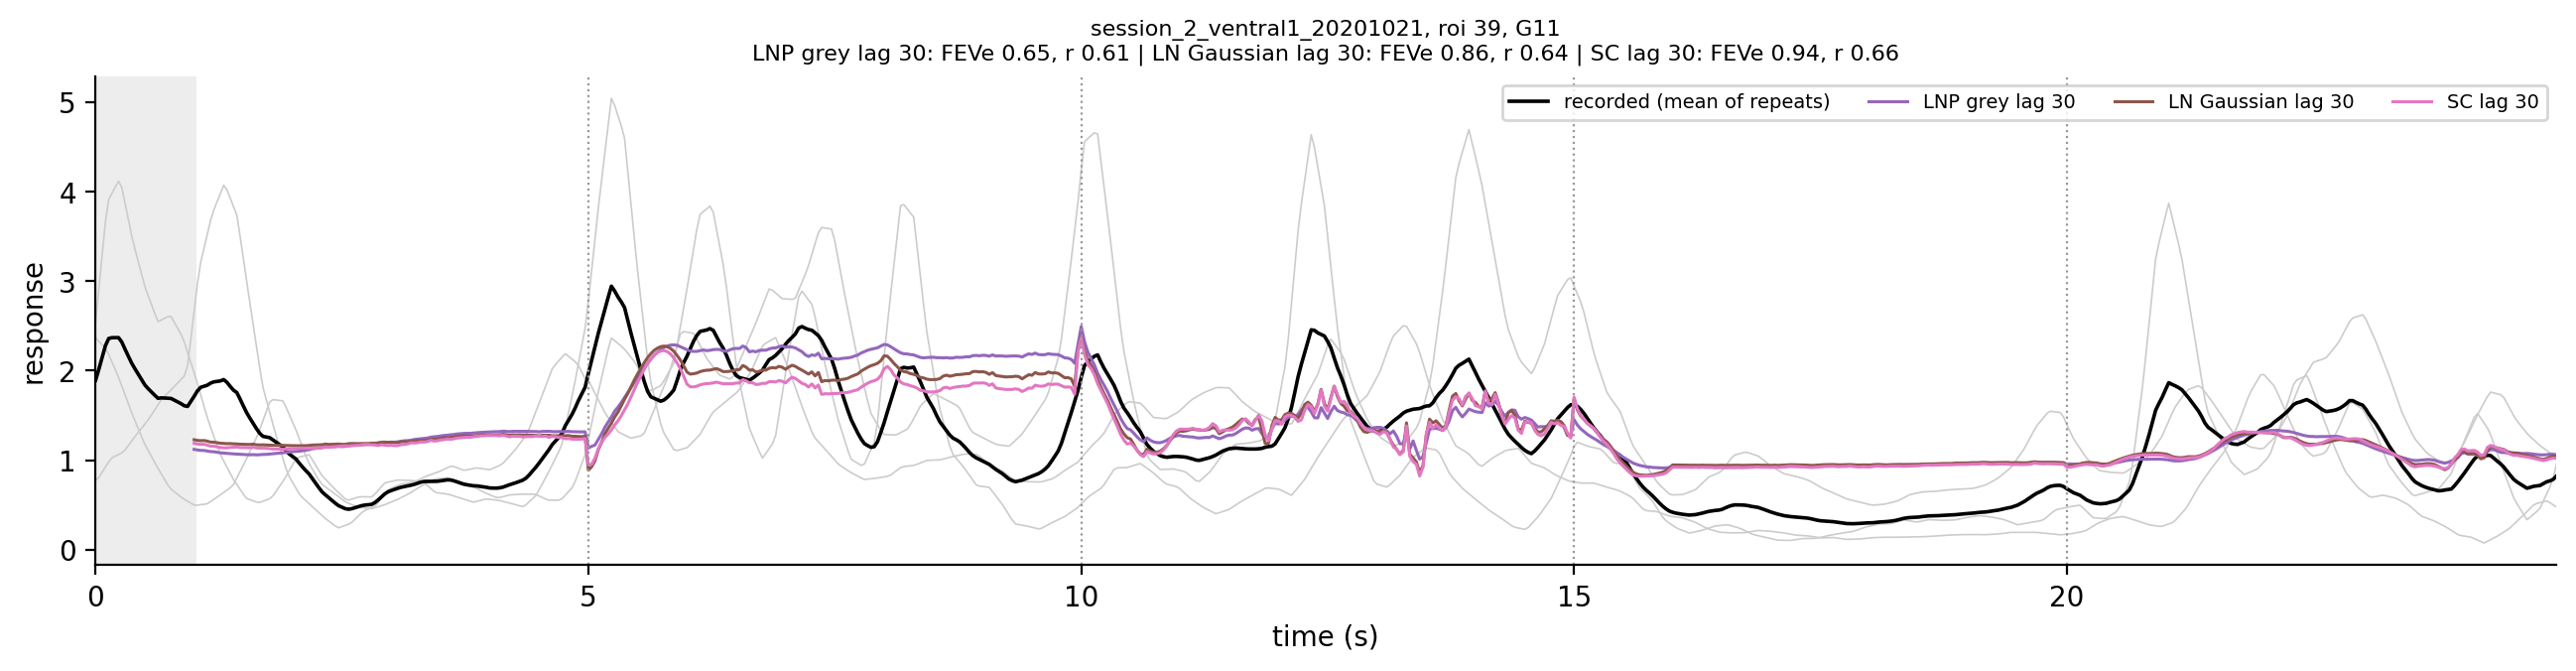

In [18]:
def plot_cell_predictions(session: str, neuron: int, model_labels: list[str], ax: plt.Axes | None = None) -> plt.Figure:
    if ax is None:
        _, ax = plt.subplots(figsize=(16, 3.2))
    by_trial = final_responses[session].test_by_trial[neuron]  # (time, trials)
    time_s = np.arange(by_trial.shape[0]) / FRAME_RATE_HZ
    ax.plot(time_s, by_trial, color="0.8", lw=0.6)
    ax.plot(time_s, by_trial.mean(axis=1), color="k", lw=1.3, label="recorded (mean of repeats)")

    scores = []
    for label in model_labels:
        prediction = predictions[label][session][:, neuron]
        lag = len(time_s) - len(prediction)
        ax.plot(time_s[lag:], prediction, color=palette[label], lw=1.1, label=label)
        row = metrics[(metrics.model == label) & (metrics.session == session) & (metrics.neuron == neuron)].iloc[0]
        scores.append(f"{label}: FEVe {row.feve:.2f}, r {row.correlation:.2f}")
    ax.axvspan(0, lag / FRAME_RATE_HZ, color="0.93", zorder=0)
    for boundary in range(CLIP_LENGTH, by_trial.shape[0], CLIP_LENGTH):
        ax.axvline(boundary / FRAME_RATE_HZ, color="0.6", ls=":", lw=0.8)

    info = cell_info.loc[(session, neuron)]
    ax.set_title(f"{session}, roi {info.roi_id}, G{info.group}\n" + " | ".join(scores), fontsize=8)
    ax.set(xlabel="time (s)", ylabel="response", xlim=(0, time_s[-1]))
    ax.legend(fontsize=7, loc="upper right", ncols=len(model_labels) + 1)
    sns.despine(ax=ax)
    return ax.figure


for session, neuron in example_cells:
    plot_cell_predictions(session, neuron, TRACE_MODELS)
    plt.show()

In [19]:
def export_all_predictions(directory: str | Path, model_labels: list[str], file_format: str = "png") -> None:
    """One figure per cell, named <session>_roi<roi id>_G<group>.<format>."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    for session in sessions:
        for neuron in range(predictions[model_labels[0]][session].shape[1]):
            figure = plot_cell_predictions(session, neuron, model_labels)
            info = cell_info.loc[(session, neuron)]
            figure.savefig(directory / f"{session}_roi{info.roi_id}_G{info.group}.{file_format}", bbox_inches="tight", dpi=150)
            plt.close(figure)
    print(f"saved {len(cell_info)} figures to {directory}")


if TRACE_EXPORT_DIR is not None:
    export_all_predictions(TRACE_EXPORT_DIR, TRACE_MODELS, TRACE_EXPORT_FORMAT)

# The contrast weight `w`

`w` scales the local spatial contrast term against the spatially weighted mean intensity: `w > 0` means contrast inside
the receptive field drives the cell beyond what its mean input explains. The LN variants fix `w = 0` and are left out.

In [20]:
w_columns = {}
for label in W_MODELS:
    model = models[label]
    if not isinstance(model, SpatialContrastCoreReadout) or not model.hparams.get("learn_contrast_weight", True):
        continue
    values = {}
    for session in sessions:
        w = model.readout[session].w.detach().cpu().numpy()
        values.update({(session, neuron): w[neuron] for neuron in range(len(w))})
    w_columns[label] = pd.Series(values)
w_wide = pd.DataFrame(w_columns)
w_wide.index.names = ["session", "neuron"]
w_long = w_wide.melt(ignore_index=False, var_name="model", value_name="w").reset_index()

w_wide.describe(percentiles=[0.1, 0.5, 0.9]).T.assign(fraction_positive=(w_wide > 0).mean()).round(3)

,count,mean,std,min,10%,50%,90%,max,fraction_positive
SC lag 0,3144.0,0.167,0.334,-1.000,-0.305,0.198,0.581,0.947,0.682
SC lag 30,3144.0,0.426,0.368,-1.144,-0.042,0.437,0.888,1.399,0.881


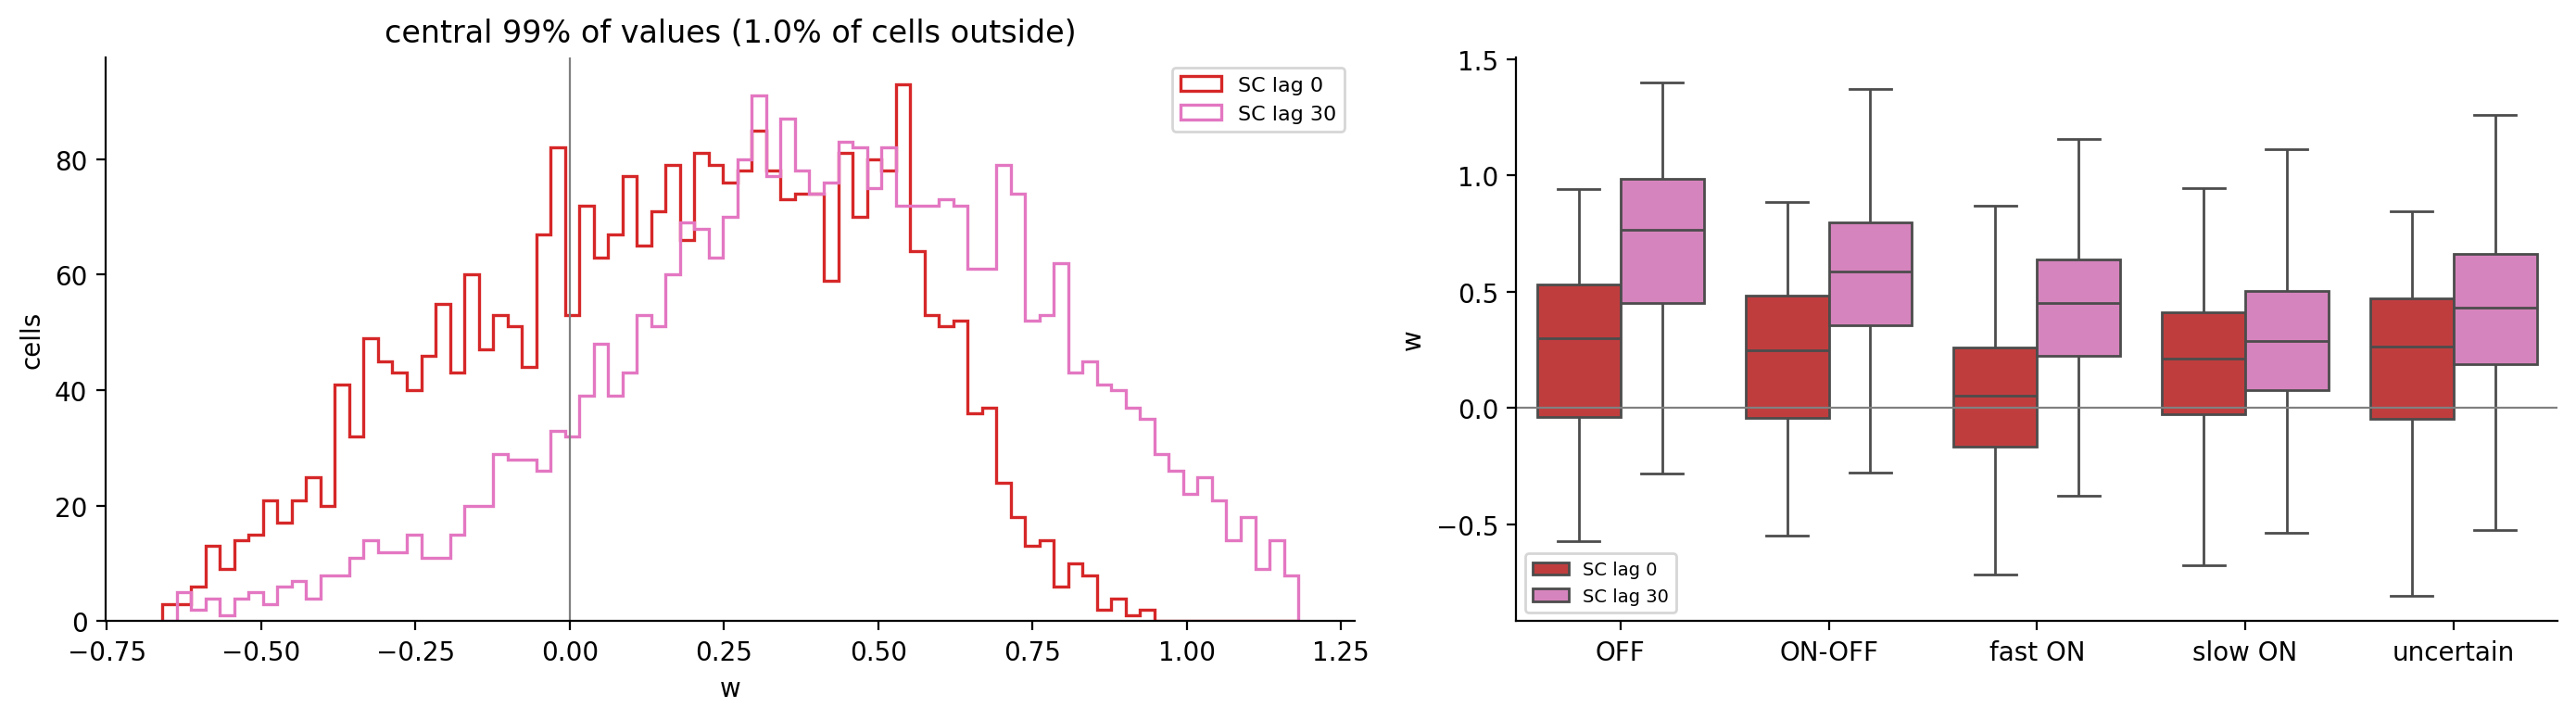

In [21]:
fig, axes = plt.subplots(ncols=2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.2, 1]})
low, high = np.nanpercentile(w_wide.values, [0.5, 99.5])
bins = np.linspace(low, high, 80)
for label in w_wide:
    axes[0].hist(w_wide[label], bins=bins, histtype="step", lw=1.2, color=palette[label], label=label)
axes[0].axvline(0, color="0.5", lw=0.8)
outside = ((w_wide < low) | (w_wide > high)).mean().mean()
axes[0].set(xlabel="w", ylabel="cells", title=f"central 99% of values ({outside:.1%} of cells outside)")
axes[0].legend(fontsize=8)

cell_groups = metrics.drop_duplicates(["session", "neuron"]).set_index(["session", "neuron"])["group_class"]
w_by_group = w_long.join(cell_groups, on=["session", "neuron"])
sns.boxplot(data=w_by_group, x="group_class", y="w", hue="model", ax=axes[1], showfliers=False,
            palette={k: palette[k] for k in w_wide})
axes[1].axhline(0, color="0.5", lw=0.8)
axes[1].set(xlabel="", ylabel="w")
axes[1].legend(fontsize=7)
sns.despine(fig=fig)
fig.tight_layout()

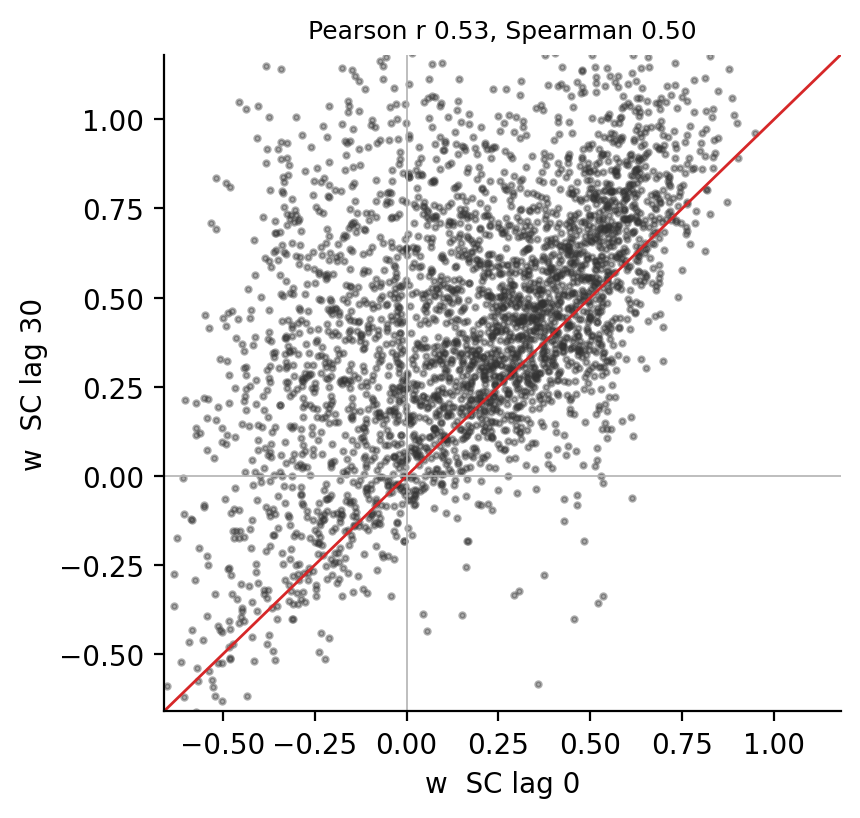

In [22]:
# Cell-by-cell comparison of w between every pair of Spatial Contrast models
pairs = list(itertools.combinations(w_wide.columns, 2))
n_cols = min(3, max(len(pairs), 1))
n_rows = int(np.ceil(len(pairs) / n_cols)) if pairs else 1
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(4.4 * n_cols, 4.2 * n_rows), squeeze=False)
for ax, (a, b) in zip(axes.flat, pairs):
    x, y = w_wide[a], w_wide[b]
    ax.scatter(x, y, s=4, alpha=0.4, color="0.2", rasterized=True)
    lo, hi = np.nanpercentile(np.r_[x, y], [0.5, 99.5])
    ax.plot([lo, hi], [lo, hi], color="tab:red", lw=1)
    ax.axhline(0, color="0.7", lw=0.6)
    ax.axvline(0, color="0.7", lw=0.6)
    ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel=f"w  {a}", ylabel=f"w  {b}")
    ax.set_title(f"Pearson r {pearsonr(x, y)[0]:.2f}, Spearman {spearmanr(x, y)[0]:.2f}", fontsize=9)
for ax in axes.flat[len(pairs) :]:
    ax.axis("off")
sns.despine(fig=fig)
fig.tight_layout()